# BV-6: free vs. XX, XpXm, XY4, UR-14 and a *learned* DD sequence

Experiment 5 of this replication. `bv6_fig1_walkthrough.ipynb` compared bare circuits with UR-14 on the single-shot
Bernstein–Vazirani circuit for $n = 6$. This notebook widens that to six ways of filling the idle gaps, plus one control:

| variant | what goes into every idle gap long enough to hold it |
|---|---|
| `free` | nothing (a bare delay) |
| `xx` | X – X |
| `xpxm` | X – X̄ (the second pulse phase-shifted by π) |
| `xy4` | X – Y – X – Y |
| `ur14` | UR-14, the sequence the BV paper used on Montreal |
| `ldd` | R – R – R† – R†, with the three Euler angles of R **learned on the QPU for this circuit** |
| `ldd_x0` | the same LDD pulses at the untrained start point x = (0, 0, 0): a control |

The `ldd` variant follows Rahman, Egger & Arenz, *"Learning How to Dynamically Decouple"* (arXiv:2405.08689).

**Why only the paper's barrier schedule.** On `ibm_fez` (walkthrough job `dar140akqcdc73abf3b0`), UR-14 helped only when
the oracle is fenced by barriers, which keeps data qubits waiting *in superposition*: `paper_free` 0.783 → `paper_ur14` 0.821.
Under ALAP the data qubits mostly wait in $|0\rangle$ and DD had no effect (0.852 vs. 0.849). Every circuit here uses the
barrier ("paper") schedule.

**Only $b = 111111$ (for now).** To save QPU time, learning and the final comparison both use just the hardest oracle,
$b = 111111$. Its six CNOTs give the longest superposition idles, and it showed the largest DD effects in the 64-oracle runs.
The final job is 7 circuits instead of 448, so each circuit can afford many more shots. `ORACLES = ALL_ORACLES` in §1 restores
the full 64-oracle sweep; every section works with either.

| Step | Section |
|---|---|
| Backend, circuit, fixed layout | §0, §1 |
| The six DD sequences, including the parameterized LDD gate | §2 |
| Build all circuits, see where the pulses go, measure coverage | §3 |
| How circuits are run (simulators and hardware share one interface) | §4 |
| Correctness gates | §5 |
| Results helpers | §6 |
| The LDD closed loop: cost function, SPSA, resumable training log | §7 |
| Offline testbed: does the loop actually learn? (toy coherent noise) | §8 |
| Noisy rehearsal and QPU budget | §9 |
| Hardware: learn x\*, then one final 7-variant job | §10, §11, §12 |
| How to read the outcome / next steps | §13 |

Like the walkthrough, this notebook does **not** import `bv_dd_lib.py`. It runs fully offline on `FakeFez` by default, and
nothing is sent to IBM unless `USE_FAKE_BACKEND = False` and one of the `SUBMIT_*` flags is set.

### What "learning dynamical decoupling" does, and how it maps onto BV

From the LDD paper (Sec. III and Fig. 1/2):

1. **The DD gate is an arbitrary rotation.** $R(\theta,\phi,\lambda) = U(\theta,\phi,\lambda) = R_Z(\phi)\,R_Y(\theta)\,R_Z(\lambda)$.
   IBM hardware runs it as $R_Z(\phi+\pi)\,\sqrt{X}\,R_Z(\theta+\pi)\,\sqrt{X}\,R_Z(\lambda)$: two physical $\sqrt{X}$ pulses
   and three *virtual* Z rotations. Only the virtual-Z angles depend on $x = (\theta,\phi,\lambda)$, so **pulse count and
   timing are identical for every x**.
2. **The sequence** in each idle gap is $\tau/2 - R - \tau - R - \tau - R^\dagger - \tau - R^\dagger - \tau/2$ (Eq. 4 with $N = 4$).
   $R R R^\dagger R^\dagger = I$ for *every* x, so the sequence never changes the computation; only the noise.
3. **Three parameters in total**, shared by every qubit and every gap. The search space does not grow with circuit size.
4. **Closed loop.** A cost $J(x)$ is estimated from hardware samples and minimized by SPSA, starting at $x_0 = (0,0,0)$ with a
   calibrated learning rate (the paper used 100 iterations, two cost evaluations each).

**Mapping to BV.** The paper prepared Bell states, so its cost needed $\langle XX\rangle, \langle YY\rangle, \langle ZZ\rangle$.
The ideal BV output is a single computational-basis state $|b\rangle$, so the fidelity is simply the success probability
$p_s$, which can be read straight off the counts:

$$J(x) = 1 - \frac{1}{|T|}\sum_{b \in T} p_s(b;\,x),$$

where $T$ is the set of training oracles (here just $b = 111111$). The learned parameters are then tested in a fresh job.

Two reference points:
* $x = (\pi, -\pi/2, \pi/2)$ makes $R = X$, so the sequence becomes X X X X.
* $x = (\pi, 0, 0)$ makes $R = Y$.

At the start point $x_0$, $R = I$: **LDD begins with no echo at all**, and the optimizer has to discover the refocusing.

In [1]:
import json
import math
import os
from collections import defaultdict
from datetime import datetime, timezone
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from qiskit import ClassicalRegister, QuantumCircuit, QuantumRegister
from qiskit.circuit import Parameter
from qiskit.circuit.library import RXGate, RZGate, SXGate, UGate, XGate
from qiskit.quantum_info import Operator
from qiskit.transpiler import PassManager
from qiskit.transpiler.passes import ALAPScheduleAnalysis, PadDelay, PadDynamicalDecoupling
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_aer import AerSimulator
from qiskit_aer.noise import NoiseModel, coherent_unitary_error

FIG_DIR = Path("figures")
RESULTS_DIR = Path("results")
FIG_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

N = 6                      # data qubits (BV-6), plus one ancilla
HEADLINE = "1" * N         # the hardest oracle: 6 CNOTs and the longest superposition idles
SEED = 7                   # transpiler / simulator / SPSA seed


def utc_now() -> str:
    return datetime.now(timezone.utc).isoformat()

## 0. Backend

`USE_FAKE_BACKEND = True` runs everything offline against `FakeFez`, a snapshot of `ibm_fez`'s calibration. It needs no
credentials and uses no QPU time. Set it to `False` only for the hardware sections (§10–§12). Credentials come from the
`MY_TOKEN` / `MY_INSTANCE` environment variables (loaded from `.env` if present), falling back to a previously saved
`QiskitRuntimeService` account. The token is never printed.

In [2]:
USE_FAKE_BACKEND = False
PREFERRED_BACKENDS = ["ibm_fez", "ibm_marrakesh"]


def load_dotenv(path=".env"):
    # Minimal KEY=VALUE loader; existing environment variables win. Values are never printed.
    if not Path(path).exists():
        return
    for line in Path(path).read_text(encoding="utf-8").splitlines():
        line = line.strip()
        if line and not line.startswith("#") and "=" in line:
            key, value = line.split("=", 1)
            os.environ.setdefault(key.strip(), value.strip().strip('"').strip("'"))


if USE_FAKE_BACKEND:
    from qiskit_ibm_runtime.fake_provider import FakeFez

    service = None
    backend = FakeFez()
else:
    from qiskit_ibm_runtime import QiskitRuntimeService

    load_dotenv()
    token, instance = os.environ.get("MY_TOKEN"), os.environ.get("MY_INSTANCE")
    if token:
        service = QiskitRuntimeService(channel="ibm_quantum_platform", token=token, instance=instance or None)
    else:
        service = QiskitRuntimeService()  # previously saved account
    available = {b.name for b in service.backends()}
    backend_name = next((name for name in PREFERRED_BACKENDS if name in available), None)
    if backend_name is None:
        raise RuntimeError(f"None of {PREFERRED_BACKENDS} available. Available: {sorted(available)}")
    backend = service.backend(backend_name)

target = backend.target
DT = target.dt                    # seconds per dt sample
DURATIONS = target.durations()    # InstructionDurations, queried in dt


def op_dt(name, qubits):
    # Calibrated duration (dt) of one instruction; virtual/unlisted ones (rz, barrier) are 0.
    try:
        return DURATIONS.get(name, list(qubits))
    except Exception:
        return 0


print(f"Backend: {backend.name}  ({backend.num_qubits} qubits){'  [offline snapshot]' if USE_FAKE_BACKEND else ''}")
print(f"dt = {DT * 1e9:.3f} ns")

qiskit_runtime_service._discover_account:WARNING:2026-10-01 22:50:31,360: Loading account with the given token. A saved account will not be used.


Backend: ibm_fez  (156 qubits)
dt = 4.000 ns


## 1. The ssBV-6 circuit and a fixed layout

Same circuit as the walkthrough's `paper` schedule:
1. The ancilla is prepared in $|1\rangle$ and every qubit gets an H.
2. A CNOT from `q_i` to the ancilla for every $b_i = 1$, fenced by barriers.
3. A final H layer, then each `q_i` is measured into `c[i]`.

The barriers keep all first H gates at the start and all final H gates at the end, so data qubits wait in superposition both
before and after their CNOT. That is the idle time DD can protect. `b[i]` is data qubit `i`, written left to right. Qiskit
count keys are little-endian, so the expected key for oracle `b` is `b[::-1]`.

**Fixed layout.** Every circuit runs on the same 7 physical qubits. On `ibm_fez` (and `FakeFez`) this is the walkthrough's
hardware layout, so `free` and `ur14` can be checked against that earlier job for drift. On any other backend the layout is
derived from transpiling $b = 111111$, as in the walkthrough.

**Which oracles.** `ORACLES` lists the oracles this run builds, learns on and tests. It is set to `[HEADLINE]`
($b = 111111$ only). Set it to `ALL_ORACLES` for all 64.

Oracles in this run: 1 ['111111']
Layout reused from walkthrough job dar140akqcdc73abf3b0: [111, 98, 109, 108, 107, 118, 110]


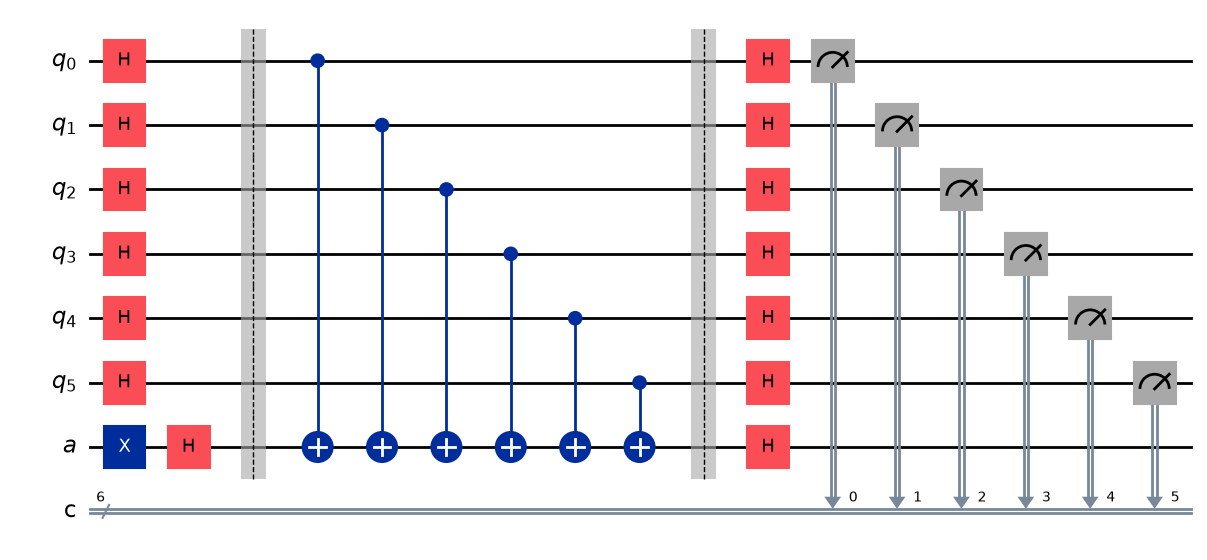

In [3]:
def build_bv(b: str) -> QuantumCircuit:
    n = len(b)
    q = QuantumRegister(n, "q")
    a = QuantumRegister(1, "a")
    c = ClassicalRegister(n, "c")
    qc = QuantumCircuit(q, a, c, name=f"bv_{b}")
    qc.x(a[0])
    qc.h(q)
    qc.h(a[0])
    qc.barrier()
    for i, bit in enumerate(b):
        if bit == "1":
            qc.cx(q[i], a[0])
    qc.barrier()
    qc.h(q)
    qc.h(a[0])
    qc.measure(q, c)
    return qc


ALL_ORACLES = [format(v, f"0{N}b") for v in range(2**N)]   # all 64, q0 = leftmost bit
ORACLES = [HEADLINE]   # only b = 111111 to save QPU time; ORACLES = ALL_ORACLES runs the full sweep
h = ORACLES.index(HEADLINE)
print(f"Oracles in this run: {len(ORACLES)} {ORACLES if len(ORACLES) <= 4 else ''}")

WALKTHROUGH_HW_JOB = "dar140akqcdc73abf3b0"
WALKTHROUGH_HW_LAYOUT = [111, 98, 109, 108, 107, 118, 110]   # q0..q5, ancilla on ibm_fez in that job

if backend.name in ("ibm_fez", "fake_fez"):
    LAYOUT = list(WALKTHROUGH_HW_LAYOUT)
    print(f"Layout reused from walkthrough job {WALKTHROUGH_HW_JOB}: {LAYOUT}")
else:
    headline_isa = generate_preset_pass_manager(optimization_level=1, backend=backend, seed_transpiler=SEED).run(
        build_bv(HEADLINE))
    LAYOUT = list(headline_isa.layout.initial_index_layout(filter_ancillas=True))
    print(f"Layout derived from transpiling b = {HEADLINE} (seed {SEED}): {LAYOUT}")

pm = generate_preset_pass_manager(optimization_level=1, backend=backend, initial_layout=LAYOUT, seed_transpiler=SEED)
ROLE = [f"q{i}" for i in range(N)] + ["anc"]
build_bv(HEADLINE).draw("mpl", fold=-1)

## 2. The DD sequences

Every sequence is built from native gates only: physical `x` / `sx` pulses plus virtual `rz` frame changes, which take no
time on IBM hardware.

**π pulse about any axis in the xy-plane.** A π pulse about the axis at angle $\varphi$ is
$(\pi)_\varphi = R_Z(\varphi)\,X\,R_Z(-\varphi) \propto \cos\varphi\,X + \sin\varphi\,Y$. In *time order* that is
`rz(-φ)`, `x`, `rz(φ)`. (The walkthrough applied them as `rz(φ)`, `x`, `rz(-φ)`, which is the mirror image $-\varphi$.
For UR-14 that is an equally valid sequence; here the order is chosen so that "Y" really is $+Y$.)

| name | pulse axes | notes |
|---|---|---|
| XX | 0, 0 | the simplest echo |
| XpXm | 0, π | X then −X: an amplitude (flip-angle) error on the first pulse is undone by the second |
| XY4 | 0, π/2, 0, π/2 | X Y X Y, universal to first order (= UR-4) |
| UR-14 | $\varphi_k$ of Appendix F, $\varphi_2 = \Phi$ | the BV paper's Montreal sequence (see the walkthrough for the $\varphi_2$ fix) |
| LDD | R, R, R†, R† | $R = U(\theta,\phi,\lambda)$ = `rz(λ)`, `sx`, `rz(θ+π)`, `sx`, `rz(φ+π)`; $R^\dagger$ is the same form at $(-\theta,-\lambda,-\phi)$ |

**Which UR?** The BV paper used UR-14 on Montreal (the speedup result) and UR-18 on Cairo. Its BV-6 output-distribution
figure (Fig. 2, 59.9% → 74.7%) comes from **Cairo with UR-18**: the authors' `bv-6_output_distribution.ipynb` loads the
`ur_18` data. This notebook keeps UR-14, for continuity with the walkthrough's hardware run.

**Spacing.** `unit_spacing` puts $\tau/2$ before the first pulse unit, $\tau$ between units and $\tau/2$ after the last, with
**zero inside a unit**. A unit is one π pulse (`rz x rz`) or one LDD gate (`rz sx rz sx rz`). `PadDynamicalDecoupling` skips
zero-length slots, so the two √X pulses of an LDD gate stay back-to-back, as in the LDD paper's Fig. 1. For π-pulse sequences
this is the same $\tau/2-\tau-\dots-\tau/2$ pattern as Qiskit's default spacing.

**Gate 1 (sequence identity).** Each sequence must compose to the identity, up to a global phase. LDD is checked at x0, at the
X- and Y-points and at 20 random points, and its two halves are checked against `UGate`.

In [4]:
def ur_big_phi(n: int) -> float:
    if n % 4 == 0:
        return math.pi / (n // 4)
    m = (n - 2) // 4
    return 2 * m * math.pi / (2 * m + 1)


def ur_phases(n: int) -> list[float]:
    # Appendix F, with phi2 = Phi for n = 4m+2 so the sequence closes to the identity (see the walkthrough, section 2).
    big_phi = ur_big_phi(n)
    phi2 = math.pi / 2 if n % 4 == 0 else big_phi
    return [((k - 1) * (k - 2) / 2) * big_phi + (k - 1) * phi2 for k in range(1, n + 1)]


def pi_unit(phi: float, label: str) -> list:
    # Time order rz(-phi), x, rz(phi): the operator R_Z(phi) X R_Z(-phi), a pi pulse about cos(phi) X + sin(phi) Y.
    return [RZGate(-phi), XGate(label=label), RZGate(phi)]


def unit_spacing(unit_sizes: list[int]) -> list[float]:
    # tau/2 before the first unit, tau between units, tau/2 after the last, 0 inside a unit. Qiskit requires
    # sum(spacing) == 1 exactly, so the last slot absorbs the float round-off.
    n = len(unit_sizes)
    spacing = [1 / (2 * n)]
    for k, size in enumerate(unit_sizes):
        spacing += [0.0] * (size - 1)
        if k < n - 1:
            spacing.append(1 / n)
    spacing.append(1 - sum(spacing))
    assert sum(spacing) == 1 and len(spacing) == sum(unit_sizes) + 1
    return spacing


def pi_sequence(name: str, phases: list[float]):
    gates = [g for k, phi in enumerate(phases, start=1) for g in pi_unit(phi, f"{name}:{k}")]
    return gates, unit_spacing([3] * len(phases))


FIXED_SEQUENCES = {
    "xx": pi_sequence("xx", [0.0, 0.0]),
    "xpxm": pi_sequence("xpxm", [0.0, math.pi]),
    "xy4": pi_sequence("xy4", [0.0, math.pi / 2, 0.0, math.pi / 2]),
    "ur14": pi_sequence("ur14", ur_phases(14)),
}

# LDD. Parameter names sort in (theta, phi, lambda) order, which is the column order SamplerV2 expects for each row of x.
LDD_PARAMS = [Parameter("x0_θ"), Parameter("x1_φ"), Parameter("x2_λ")]
X0 = np.zeros(3)                                    # the paper's start point: R = I
X_POINT = np.array([math.pi, -math.pi / 2, math.pi / 2])   # R = X
Y_POINT = np.array([math.pi, 0.0, 0.0])             # R = Y
LDD_ROLES = ["fwd", "fwd", "inv", "inv"]            # R, R, R^dag, R^dag (LDD paper Eq. 4, N = 4)


def ldd_rz_angles(role, theta, phi, lam):
    # Virtual-Z angles, in time order, around the two sqrt(X) pulses of one LDD gate.
    # fwd: U(theta, phi, lam) = rz(lam) sx rz(theta+pi) sx rz(phi+pi), up to a global phase.
    # inv: U^dag = U(-theta, -lam, -phi), the same form with the angles swapped and negated.
    if role == "inv":
        theta, phi, lam = -theta, -lam, -phi
    return [lam, theta + math.pi, phi + math.pi]


def ldd_gates(x) -> list:
    gates = []
    for k, role in enumerate(LDD_ROLES, start=1):
        angles = ldd_rz_angles(role, *x)
        for s in range(3):
            gates.append(RZGate(angles[s], label=f"ldd:{k}:{role}:{s}"))
            if s < 2:
                gates.append(SXGate(label=f"ldd:{k}:sx{s}"))
    return gates


LDD_SPACING = unit_spacing([5] * len(LDD_ROLES))
LDD_PLACEHOLDER = (0.3, 0.7, 1.1)   # any x passes the identity check; swapped for Parameters after padding (section 3)

SEQ_GATES = {name: gates for name, (gates, _) in FIXED_SEQUENCES.items()} | {"ldd": ldd_gates(LDD_PLACEHOLDER)}
SEQ_SPACING = {name: sp for name, (_, sp) in FIXED_SEQUENCES.items()} | {"ldd": LDD_SPACING}
DD_NAMES = list(SEQ_GATES)   # ['xx', 'xpxm', 'xy4', 'ur14', 'ldd']


def product(gates) -> np.ndarray:
    u = np.eye(2, dtype=complex)
    for g in gates:
        u = Operator(g).data @ u
    return u


def is_identity(u) -> bool:
    return Operator(u).equiv(Operator(np.eye(2)))


# Gate 1a: every fixed sequence is the identity, and pi_unit really points along cos(phi) X + sin(phi) Y.
for name, gates in SEQ_GATES.items():
    assert is_identity(product(gates)), name
for phi in np.linspace(0, 2 * np.pi, 9):
    axis = np.cos(phi) * np.array([[0, 1], [1, 0]]) + np.sin(phi) * np.array([[0, -1j], [1j, 0]])
    assert Operator(product(pi_unit(phi, "t"))).equiv(Operator(axis)), phi

# Gate 1b: LDD is the identity at every x, and its first / third gates are U(x) and U(x)^dag.
ldd_points = [X0, X_POINT, Y_POINT, *np.random.default_rng(SEED).uniform(-np.pi, np.pi, (20, 3))]
for x in ldd_points:
    g = ldd_gates(x)
    assert is_identity(product(g))
    assert Operator(product(g[0:5])).equiv(Operator(UGate(*x)))
    assert Operator(product(g[10:15])).equiv(Operator(UGate(*x)).adjoint())
assert Operator(UGate(*X_POINT)).equiv(Operator(XGate())) and Operator(UGate(*Y_POINT)).equiv(Operator(np.array([[0, -1j], [1j, 0]])))
print(f"Gate 1 passed: 4 fixed sequences and LDD at {len(ldd_points)} parameter points compose to the identity; "
      "LDD gates match U(θ,φ,λ) and its inverse.")


def sequence_dt(seq: str, q: int) -> int:
    return sum(op_dt(g.name, [q]) for g in SEQ_GATES[seq])


rows = []
for seq in DD_NAMES:
    pulses = [g for g in SEQ_GATES[seq] if g.name in ("x", "sx")]
    need = sequence_dt(seq, LAYOUT[0])
    rows.append({"sequence": seq, "physical pulses": f"{len(pulses)} x {'√X' if pulses[0].name == 'sx' else 'X'}",
                 "shortest gap it fits (dt)": need, "shortest gap (ns)": round(need * DT * 1e9),
                 "learned parameters": 3 if seq == "ldd" else 0})
display(pd.DataFrame(rows).set_index("sequence"))

Gate 1 passed: 4 fixed sequences and LDD at 23 parameter points compose to the identity; LDD gates match U(θ,φ,λ) and its inverse.


,physical pulses,shortest gap it fits (dt),shortest gap (ns),learned parameters
sequence,,,,
xx,2 x X,12,48,0
xpxm,2 x X,12,48,0
xy4,4 x X,24,96,0
ur14,14 x X,84,336,0
ldd,8 x √X,48,192,3


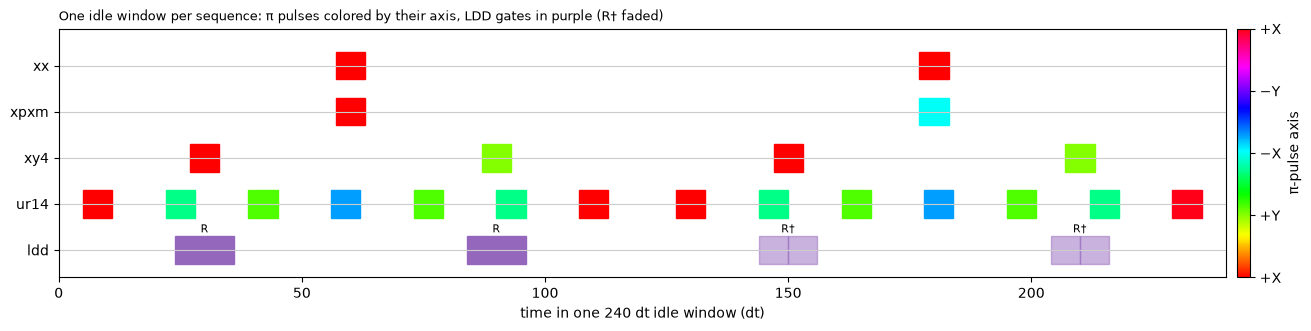

In [5]:
VARIANT_COLORS = {"free": "0.35", "xx": "tab:orange", "xpxm": "tab:green", "xy4": "tab:red", "ur14": "tab:cyan",
                  "ldd": "tab:purple", "ldd_x0": "plum"}


def place_in_window(gates, spacing, window_dt, q):
    # Where PadDynamicalDecoupling puts each pulse in one idle window: floor(slack * spacing) per slot, and the
    # leftover dt go to the middle slot.
    durs = [op_dt(g.name, [q]) for g in gates]
    slack = window_dt - sum(durs)
    taus = np.floor(slack * np.asarray(spacing))
    taus[(len(taus) - 1) // 2] += slack - taus.sum()
    t, placed, frame = 0.0, [], 0.0
    for tau, g, d in zip(taus, gates, durs):
        t += tau
        if g.name == "rz":
            frame = float(g.params[0])
        else:
            placed.append((g, t, d, -frame))   # axis of a pi_unit pulse = minus the frame change just before it
        t += d
    return placed


WINDOW = 240   # dt, roughly one long superposition gap of the headline circuit
axis_cmap = plt.get_cmap("hsv")
fig, ax = plt.subplots(figsize=(13, 3.2), layout="constrained")
for row, seq in enumerate(DD_NAMES):
    y = len(DD_NAMES) - 1 - row
    ax.hlines(y, 0, WINDOW, color="0.8", lw=0.8)
    for g, t, d, axis in place_in_window(SEQ_GATES[seq], SEQ_SPACING[seq], WINDOW, LAYOUT[0]):
        if seq == "ldd":
            k = int(g.label.split(":")[1])
            ax.add_patch(plt.Rectangle((t, y - 0.3), d, 0.6, color=VARIANT_COLORS["ldd"], alpha=1.0 if k <= 2 else 0.5))
            if g.label.endswith("sx0"):
                ax.text(t + d, y + 0.38, "R" if k <= 2 else "R†", ha="center", fontsize=8)
        else:
            ax.add_patch(plt.Rectangle((t, y - 0.3), d, 0.6, color=axis_cmap((axis % (2 * np.pi)) / (2 * np.pi))))
ax.set_yticks(range(len(DD_NAMES)), DD_NAMES[::-1])
ax.set_xlim(0, WINDOW)
ax.set_ylim(-0.6, len(DD_NAMES) - 0.2)
ax.set_xlabel(f"time in one {WINDOW} dt idle window (dt)")
ax.set_title("One idle window per sequence: π pulses colored by their axis, LDD gates in purple (R† faded)",
             fontsize=9, loc="left")
cbar = fig.colorbar(plt.cm.ScalarMappable(cmap=axis_cmap, norm=plt.Normalize(0, 360)), ax=ax, pad=0.01)
cbar.set_ticks([0, 90, 180, 270, 360], labels=["+X", "+Y", "−X", "−Y", "+X"])
cbar.set_label("π-pulse axis")
plt.show()

## 3. Build every circuit

For each oracle in `ORACLES`:
1. Transpile once (fixed layout, Sabre routing, seed 7).
2. ALAP-schedule, then either fill the gaps with `Delay` (**free**) or run `PadDynamicalDecoupling` once per sequence. A
   gap shorter than one full sequence is left bare, as in the paper. §3c counts those gaps.

**Making the LDD angles learnable.** `PadDynamicalDecoupling` multiplies the sequence's matrices together to check it is the
identity, so it cannot take unbound `Parameter`s. The LDD circuits are therefore padded with numeric placeholder angles
(R R R† R† is the identity for any x), and the labelled `rz` gates are then swapped *in place* for expressions such as
`x0_θ + π`. Each oracle gets **one parameterized ISA circuit**, and any number of parameter points x can be evaluated in one
`SamplerV2` PUB `(circuit, X[K, 3])`.

In [6]:
free_pm = PassManager([ALAPScheduleAnalysis(target=target), PadDelay(target=target)])


def dd_pass_manager(gates, spacing):
    return PassManager([ALAPScheduleAnalysis(target=target),
                        PadDynamicalDecoupling(target=target, dd_sequence=gates, spacing=spacing)])


DD_PMS = {seq: dd_pass_manager(SEQ_GATES[seq], SEQ_SPACING[seq]) for seq in DD_NAMES}


def parametrize_ldd(padded: QuantumCircuit) -> QuantumCircuit:
    # Replace each LDD frame change's placeholder angle with an expression of the shared Parameters. The swap happens
    # in place on a copy, so the schedule (op_start_times) and the duration are untouched.
    circ = padded.copy()
    for idx, inst in enumerate(circ.data):
        label = inst.operation.label or ""
        if inst.operation.name == "rz" and label.startswith("ldd:"):
            _, _, role, slot = label.split(":")
            circ.data[idx] = inst.replace(operation=RZGate(ldd_rz_angles(role, *LDD_PARAMS)[int(slot)], label=label))
    return circ


def bind(circ: QuantumCircuit, x) -> QuantumCircuit:
    return circ.assign_parameters(dict(zip(LDD_PARAMS, map(float, x)))) if circ.parameters else circ


BASE_VARIANTS = ["free"] + DD_NAMES
circuits = {v: [] for v in BASE_VARIANTS}   # circuits[variant] is a list aligned with ORACLES
FINAL_LAYOUT = {}                           # oracle -> physical qubit holding each virtual qubit at measurement
for b in ORACLES:
    isa = pm.run(build_bv(b))
    free = free_pm.run(isa)
    free.name = f"bv_{b}_free"
    circuits["free"].append(free)
    for seq, dd_pm in DD_PMS.items():
        c = dd_pm.run(isa)
        c.name = f"bv_{b}_{seq}"
        circuits[seq].append(parametrize_ldd(c) if seq == "ldd" else c)
    FINAL_LAYOUT[b] = isa.layout.final_index_layout(filter_ancillas=True)
assert all(list(c.parameters) == LDD_PARAMS for c in circuits["ldd"])

display(pd.DataFrame({"virtual": ROLE, "initial physical": LAYOUT, "physical at measurement": FINAL_LAYOUT[HEADLINE]})
        .set_index("virtual").T)


def dd_label(op):
    # Name of the DD sequence a pulse belongs to, or None for circuit gates.
    head = (op.label or "").split(":")[0]
    return head if op.name in ("x", "sx") and head in DD_NAMES else None


rows = []
for v in BASE_VARIANTS:
    c = circuits[v][h]
    dd_pulses = sum(1 for inst in c.data if dd_label(inst.operation) == v)
    per_rep = sum(1 for g in SEQ_GATES[v] if g.name in ("x", "sx")) if v != "free" else 1
    dur = c.estimate_duration(target, unit="dt")
    rows.append({"variant": v, "duration (dt)": dur, "duration (us)": round(dur * DT * 1e6, 3),
                 "CZ": c.count_ops().get("cz", 0), "DD pulses": dd_pulses,
                 "gaps filled": dd_pulses // per_rep if v != "free" else 0, "free parameters": len(c.parameters)})
print(f"{len(BASE_VARIANTS)} variants x {len(ORACLES)} oracles built. Headline oracle b = {HEADLINE}:")
display(pd.DataFrame(rows).set_index("variant"))

virtual,q0,q1,q2,q3,q4,q5,anc
initial physical,111,98,109,108,107,118,110
physical at measurement,98,111,110,107,108,118,109


6 variants x 1 oracles built. Headline oracle b = 111111:


,duration (dt),duration (us),CZ,DD pulses,gaps filled,free parameters
variant,,,,,,
free,754,3.016,15,0,0,0
xx,754,3.016,15,26,13,0
xpxm,754,3.016,15,26,13,0
xy4,754,3.016,15,44,11,0
ur14,754,3.016,15,112,8,0
ldd,754,3.016,15,80,10,3


### 3b. Where the pulses go (headline oracle, oracle region)

The walkthrough's custom timeline, with each sequence in its own color:
* grey boxes: √X pulses that belong to the circuit (H gates and CNOT basis changes)
* blue: CZ
* colored: DD pulses (for LDD, the R† pulses are faded)
* dashed red: the barriers

The plot stops just after the measurements start.

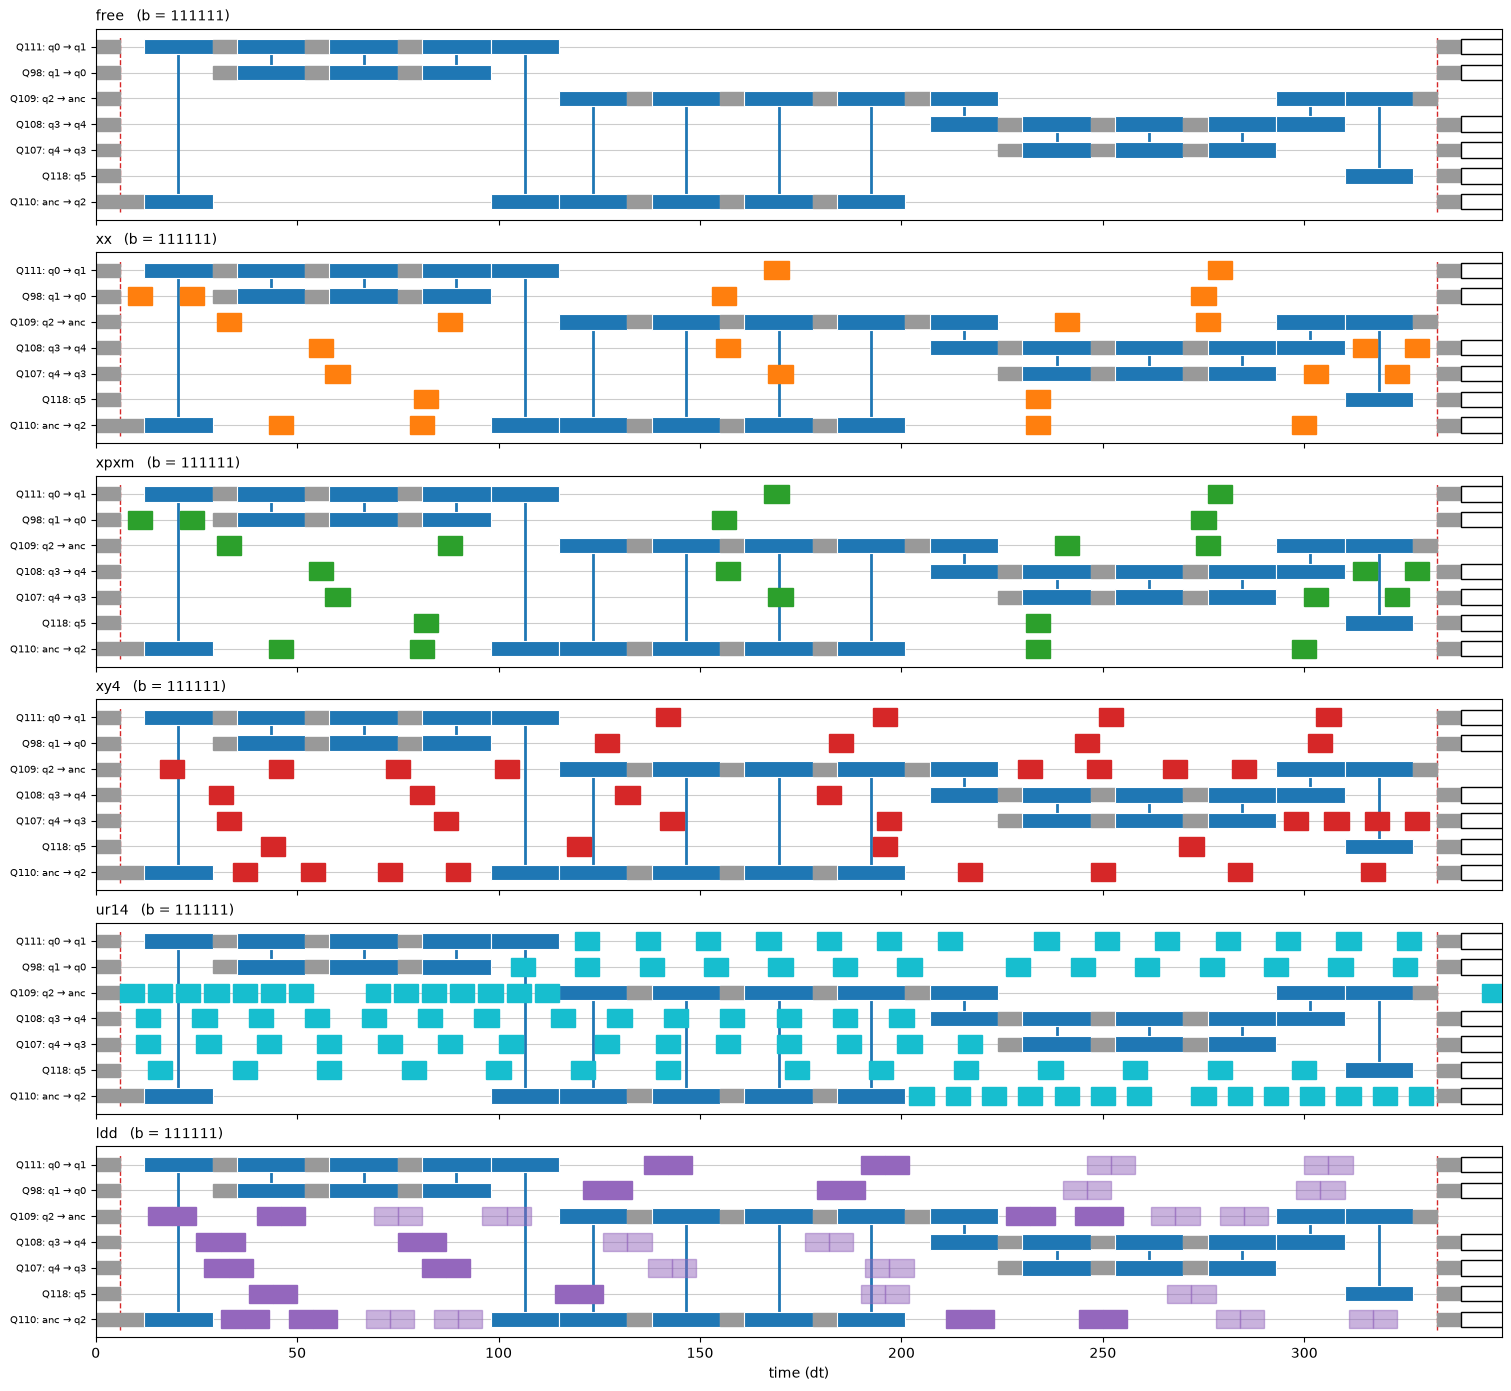

In [7]:
def instructions_with_times(circ):
    for inst, t0 in zip(circ.data, circ.op_start_times):
        qs = [circ.find_bit(q).index for q in inst.qubits]
        name = inst.operation.name
        dur = inst.operation.duration if name == "delay" else op_dt(name, qs)
        yield inst.operation, qs, t0, dur


def row_order(circ):
    active = {q for op, qs, _, _ in instructions_with_times(circ) if op.name not in ("delay", "barrier") for q in qs}
    return list(LAYOUT) + sorted(active - set(LAYOUT))


def row_label(b, phys):
    fin = FINAL_LAYOUT[b]
    start = ROLE[LAYOUT.index(phys)] if phys in LAYOUT else "routing"
    end = ROLE[fin.index(phys)] if phys in fin else "routing"
    return f"Q{phys}: {start}" + ("" if start == end else f" → {end}")


def plot_timeline(circ, b, ax, title, t_max=None):
    rows = row_order(circ)
    y = {p: len(rows) - 1 - i for i, p in enumerate(rows)}
    total = t_max or circ.estimate_duration(target, unit="dt")
    for p in rows:
        ax.hlines(y[p], 0, total, color="0.8", lw=0.8, zorder=0)
    for op, qs, t0, dur in instructions_with_times(circ):
        name = op.name
        if t0 > total:
            continue
        if name == "barrier":
            ys = [y[q] for q in qs if q in y]
            if ys:
                ax.vlines(t0, min(ys) - 0.4, max(ys) + 0.4, color="tab:red", ls="--", lw=1, zorder=1)
            continue
        if name in ("delay", "rz") or not all(q in y for q in qs):
            continue
        seq = dd_label(op)
        if name == "cz":
            for q in qs:
                ax.add_patch(plt.Rectangle((t0, y[q] - 0.3), dur, 0.6, fc="tab:blue", ec="white", lw=0.8, zorder=2))
            ax.vlines(t0 + dur / 2, min(y[q] for q in qs), max(y[q] for q in qs), color="tab:blue", lw=2, zorder=1)
        elif seq is not None:
            faded = seq == "ldd" and int(op.label.split(":")[1]) > 2
            ax.add_patch(plt.Rectangle((t0, y[qs[0]] - 0.35), dur, 0.7, color=VARIANT_COLORS[seq],
                                       alpha=0.5 if faded else 1.0, zorder=3))
        elif name == "measure":
            ax.add_patch(plt.Rectangle((t0, y[qs[0]] - 0.3), dur, 0.6, fc="white", ec="k", zorder=2))
        else:
            ax.add_patch(plt.Rectangle((t0, y[qs[0]] - 0.25), max(dur, 1), 0.5, color="0.6", zorder=2))
    ax.set_yticks([y[p] for p in rows], [row_label(b, p) for p in rows], fontsize=7)
    ax.set_xlim(0, total)
    ax.set_ylim(-0.7, len(rows) - 0.3)
    ax.set_title(title, fontsize=10, loc="left")


meas_start = min(t for op, _, t, _ in instructions_with_times(circuits["free"][h]) if op.name == "measure")
fig, axes = plt.subplots(len(BASE_VARIANTS), 1, figsize=(15, 2.3 * len(BASE_VARIANTS)), sharex=True, layout="constrained")
for ax, v in zip(axes, BASE_VARIANTS):
    plot_timeline(circuits[v][h], HEADLINE, ax, f"{v}   (b = {HEADLINE})", t_max=meas_start + 10)
axes[-1].set_xlabel("time (dt)")
fig.savefig(FIG_DIR / "bv6_ldd_timeline_headline.png", dpi=120, bbox_inches="tight")
plt.show()

### 3c. How much superposition idle time does each sequence protect?

Same classification as the walkthrough. Each idle gap of the free circuit is labelled `|0>` (before the qubit's first gate),
`superposition`, or `unmeasured tail`. The figure of merit is the **% of superposition idle time that received a sequence**.
A gap only receives a sequence if it is *strictly longer* than the sequence's pulses: XX needs more than 12 dt, LDD more
than 48 dt, UR-14 more than 84 dt. `PadDynamicalDecoupling` needs slack > 0, so a gap of exactly one sequence length stays
bare. The longer a sequence, the more gaps it misses. That is part of the result and is not corrected for. §12 plots each
sequence's gain against this coverage.

In [8]:
def idle_coverage(free, dd, seq):
    first_gate, last_cz_end, meas_end = {}, defaultdict(int), {}
    for op, qs, t0, dur in instructions_with_times(free):
        if op.name in ("delay", "barrier", "rz"):
            continue
        for q in qs:
            first_gate[q] = min(first_gate.get(q, t0), t0)
            if op.name == "cz":
                last_cz_end[q] = max(last_cz_end[q], t0 + dur)
            if op.name == "measure":
                meas_end[q] = t0 + dur
    dd_starts = defaultdict(list)
    for op, qs, t0, _ in instructions_with_times(dd):
        if dd_label(op) == seq:
            dd_starts[qs[0]].append(t0)

    rows = []
    for op, qs, t0, dur in instructions_with_times(free):
        q = qs[0]
        if op.name != "delay" or q not in first_gate or dur == 0:
            continue
        t1 = t0 + dur
        if t1 <= first_gate[q]:
            state = "|0>"
        elif q not in meas_end and t0 >= last_cz_end[q]:
            state = "unmeasured tail"
        elif q in meas_end and t0 >= meas_end[q]:
            state = "after measurement"
        else:
            state = "superposition"
        if any(t0 <= s < t1 for s in dd_starts[q]):
            status = "DD inserted"
        elif state != "superposition":
            status = "no DD needed"
        elif dur <= sequence_dt(seq, q):   # the pass needs slack > 0: a gap of exactly one sequence stays bare
            status = "too short (bare)"
        else:
            status = "skipped by pass (bare)"
        rows.append({"qubit": q, "length (dt)": dur, "state": state, "status": status})
    return pd.DataFrame(rows)


def coverage_summary(df):
    sup = df[df["state"] == "superposition"]
    total = sup["length (dt)"].sum()
    covered = sup.loc[sup["status"] == "DD inserted", "length (dt)"].sum()
    return {"% protected": 100 * covered / total if total else float("nan"),
            "superposition idle (dt)": total,
            "gaps too short": int((sup["status"] == "too short (bare)").sum()),
            "gaps skipped by pass": int((sup["status"] == "skipped by pass (bare)").sum())}


COVERAGE = {}   # seq -> % of superposition idle time protected, per oracle (aligned with ORACLES)
rows = []
for seq in DD_NAMES:
    per = [coverage_summary(idle_coverage(f, d, seq)) for f, d in zip(circuits["free"], circuits[seq])]
    COVERAGE[seq] = [p["% protected"] for p in per]
    rows.append({"sequence": seq, "shortest gap it fits (dt)": sequence_dt(seq, LAYOUT[0]),
                 f"% protected (b={HEADLINE})": per[h]["% protected"],
                 "% protected (mean over oracles)": np.nanmean(COVERAGE[seq]),
                 f"gaps too short (b={HEADLINE})": per[h]["gaps too short"],
                 "gaps skipped by pass (all oracles)": sum(p["gaps skipped by pass"] for p in per)})
COVERAGE["ldd_x0"] = COVERAGE["ldd"]
display(pd.DataFrame(rows).set_index("sequence").round(1))

,shortest gap it fits (dt),% protected (b=111111),% protected (mean over oracles),gaps too short (b=111111),gaps skipped by pass (all oracles)
sequence,,,,,
xx,12,99.3,99.3,2,0
xpxm,12,99.3,99.3,2,0
xy4,24,96.5,96.5,4,0
ur14,84,85.7,85.7,7,0
ldd,48,94.1,94.1,5,0


## 4. How circuits are run

There is one interface for every engine. A **PUB** is `(circuit, X)`, where `X` is either `None` (a circuit with no
parameters) or a `(K, 3)` array of LDD parameter points. Every runner returns `counts[pub][row]`, positionally aligned with
its input. Circuits are never keyed by name.

**Simulation gotcha.** When a gate has a label, Aer's noise models look up its errors under the *label*, not the gate name.
The DD pulses carry labels (`xx:1`, `ldd:2:sx0`, …) so they can be drawn and counted. Left as they are, they would run
**noiseless** in the noisy simulator. `run_offline` therefore strips every label before simulating. Hardware ignores labels.
(The walkthrough labels its UR-14 pulses `P1`…`P14`, so its noisy-simulation numbers treated those pulses as perfect.)

| engine | what it is |
|---|---|
| `"ideal"` | noiseless `AerSimulator` |
| `"noisy"` | `AerSimulator.from_backend`: T1/T2, gate and readout errors from the calibration snapshot |
| `"toy"` | the coherent toy noise of §8 (quasi-static detuning plus pulse over-rotation) |
| hardware | Runtime `SamplerV2` with Runtime's own DD **and** twirling turned off, so the only DD on the chip is ours. Parameterized PUBs go up as-is, so K parameter points cost one job. |

**Training set.** The cost $J(x)$ averages $p_s$ over the oracles in `ORACLES` with Hamming weight ≥ 5. Their data qubits
wait longest in superposition, so they carry the largest DD signal. With `ORACLES = [HEADLINE]` that is just $b = 111111$.
With all 64 oracles it is the six weight-5 oracles plus $b = 111111$, where every data qubit appears symmetrically.

**Shots per point.** Each parameter point gets `TRAIN_SHOTS_PER_POINT` = 1750 shots in total, split evenly over the training
oracles: 1750 on $b = 111111$ alone, or 250 each with 7 oracles. That keeps the shot noise of J at σ_J ≈ 0.01 either way,
and keeps the same billed cost per job as the first hardware run.

In [9]:
TRAIN = [b for b in ORACLES if b.count("1") >= 5]
TRAIN_IDX = [ORACLES.index(b) for b in TRAIN]
TRAIN_SHOTS_PER_POINT = 1750                                # shots per parameter point, over all training oracles
TRAIN_SHOTS = TRAIN_SHOTS_PER_POINT // len(TRAIN)           # per training oracle, per parameter point
BASELINE_VARIANTS = ["free", "xx", "xpxm", "xy4", "ur14"]   # the fixed sequences


def expected_key(b: str) -> str:
    return b[::-1]   # Qiskit keys are little-endian: c5 ... c0


def success_prob(counts: dict, b: str) -> float:
    return counts.get(expected_key(b), 0) / sum(counts.values())


_SIMS = {}
_sim_calls = iter(range(10**9))   # a fresh, reproducible simulator seed for every call


def simulator(kind: str):
    if kind not in _SIMS:
        if kind == "ideal":
            _SIMS[kind] = AerSimulator()
        elif kind == "noisy":
            _SIMS[kind] = AerSimulator.from_backend(backend)
        else:
            raise ValueError(f"unknown engine {kind!r} (the toy engine is set up in section 8)")
    return _SIMS[kind]


def pub_rows(X) -> int:
    return 1 if X is None else len(np.atleast_2d(X))


def unlabelled(circ: QuantumCircuit) -> QuantumCircuit:
    # Aer looks up noise-model errors by a gate's *label* when it has one, so a labelled DD pulse would run noiseless.
    out = circ.copy()
    for idx, inst in enumerate(out.data):
        if inst.operation.label:
            op = inst.operation.to_mutable()
            op.label = None
            out.data[idx] = inst.replace(operation=op)
    return out


def run_offline(pubs, shots: int, engine: str = "ideal"):
    flat, where = [], []
    for i, (circ, X) in enumerate(pubs):
        for r, x in enumerate([None] if X is None else np.atleast_2d(X)):
            flat.append(unlabelled(circ if x is None else bind(circ, x)))
            where.append((i, r))
    if engine == "toy":
        counts = toy_run(flat, shots)   # defined in section 8
    else:
        counts = simulator(engine).run(flat, shots=shots, seed_simulator=SEED + next(_sim_calls)).result().get_counts()
        counts = [counts] if len(flat) == 1 else counts
    out = [[None] * pub_rows(X) for _, X in pubs]
    for (i, r), c in zip(where, counts):
        out[i][r] = c
    return out


def submit_hardware(pubs, shots: int):
    from qiskit_ibm_runtime import SamplerV2

    sampler = SamplerV2(mode=backend)
    sampler.options.dynamical_decoupling.enable = False   # our sequences only
    sampler.options.twirling.enable_gates = False
    sampler.options.twirling.enable_measure = False
    return sampler.run([(c,) if X is None else (c, np.atleast_2d(X)) for c, X in pubs], shots=shots)


def collect_hardware(job, pubs):
    result = job.result()   # blocks until the job has run, including queue time
    out = []
    for (_, X), pub in zip(pubs, result):
        bits = pub.data.c
        out.append([bits.get_counts()] if X is None else [bits.get_counts(r) for r in range(pub_rows(X))])
    return out


def training_cost(counts_by_pub) -> np.ndarray:
    # counts_by_pub[j][r]: training oracle TRAIN[j], parameter row r. Returns J = 1 - mean p_s for every row.
    rows = len(counts_by_pub[0])
    return np.array([1 - np.mean([success_prob(counts_by_pub[j][r], b) for j, b in enumerate(TRAIN)])
                     for r in range(rows)])


print(f"Training oracles ({len(TRAIN)}): {TRAIN}, {TRAIN_SHOTS} shots each per parameter point")

Training oracles (1): ['111111'], 1750 shots each per parameter point


## 5. Correctness gates

These must pass before any hardware run. A failure here means the construction is wrong, not that DD failed.

1. **Every sequence is the identity** (§2).
2. **DD only fills idle time.** Every DD variant has the same total duration as `free`, and every circuit gate (√X, X, CZ,
   measure) starts at exactly the same time.
3. **Ideal simulation gives $p_s = 1$** for every fixed variant on every oracle in `ORACLES`. For LDD the same must hold at
   x0, at the X-point and at 5 random parameter points. Learning cannot break the algorithm, whatever x it finds.

In [10]:
def fixed_gate_times(circ):
    return sorted((op.name, tuple(qs), t0) for op, qs, t0, _ in instructions_with_times(circ)
                  if op.name in ("sx", "x", "cz", "measure") and dd_label(op) is None)


for seq in DD_NAMES:
    for free, dd in zip(circuits["free"], circuits[seq]):
        assert free.estimate_duration(target, unit="dt") == dd.estimate_duration(target, unit="dt"), dd.name
        assert fixed_gate_times(free) == fixed_gate_times(dd), dd.name
print(f"Gate 2 passed: no DD variant changed a duration or moved a circuit gate ({len(DD_NAMES)} x {len(ORACLES)} pairs).")

IDEAL_POINTS = {"x0": X0, "X-point": X_POINT,
                **{f"random {k}": x for k, x in enumerate(np.random.default_rng([SEED, 3]).uniform(-np.pi, np.pi, (5, 3)), 1)}}
X_IDEAL = np.array(list(IDEAL_POINTS.values()))
pubs = [(c, None) for v in BASELINE_VARIANTS for c in circuits[v]] + [(c, X_IDEAL) for c in circuits["ldd"]]
ideal = run_offline(pubs, shots=100, engine="ideal")
n_fixed = len(BASELINE_VARIANTS) * len(ORACLES)
ideal_ps = {v: min(success_prob(ideal[j * len(ORACLES) + i][0], b) for i, b in enumerate(ORACLES))
            for j, v in enumerate(BASELINE_VARIANTS)}
for r, name in enumerate(IDEAL_POINTS):
    ideal_ps[f"ldd @ {name}"] = min(success_prob(ideal[n_fixed + i][r], b) for i, b in enumerate(ORACLES))
display(pd.Series(ideal_ps, name=f"min p_s over {len(ORACLES)} oracle(s) (ideal)").to_frame().T)
assert all(p == 1.0 for p in ideal_ps.values()), ideal_ps
print(f"Gate 3 passed: ideal p_s = 1 for {n_fixed} fixed-variant circuits and {len(ORACLES) * len(IDEAL_POINTS)} LDD circuits.")

Gate 2 passed: no DD variant changed a duration or moved a circuit gate (5 x 1 pairs).


,free,xx,xpxm,xy4,ur14,ldd @ x0,ldd @ X-point,ldd @ random 1,ldd @ random 2,ldd @ random 3,ldd @ random 4,ldd @ random 5
min p_s over 1 oracle(s) (ideal),1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


Gate 3 passed: ideal p_s = 1 for 5 fixed-variant circuits and 7 LDD circuits.


## 6. Results helpers (shared by the toy testbed, the noisy rehearsal and the hardware run)

* **Final batch.** Every oracle in `ORACLES` × 7 variants: the five fixed variants, `ldd` bound at the learned x\*, and
  `ldd_x0` bound at (0,0,0). The batch is **oracle-major**, so the variants of one oracle sit next to each other in the job
  and slow drift during the job hits all of them alike.
* `summary_table`:
  * mean $p_s \pm 5\sigma$ (binomial, as in the paper and the walkthrough), the minimum, and the number of oracles above ½;
  * the gain $\Delta p_s$ over `free`, with a 95% CI. With several oracles the CI is a bootstrap over oracles. With one
    oracle it comes from the binomial shot noise of both variants.
  * how many oracles improved.
* `plot_ps_summary`: $p_s$ against Hamming weight when there are several weights; with one oracle, a bar per variant.
* `plot_output_distributions`:
  * Several oracles: the paper's Fig. 2 layout, oracle × detected bitstring.
  * One oracle: one row per variant across all 64 possible outputs, on a log color scale, which shows where the wrong
    answers land.
* `plot_gain_vs_coverage`: each sequence's gain against the share of idle time it protected.

For reference, the paper's BV-6 figure reports **59.9 ± 0.4%** without DD and **74.7 ± 0.3%** with DD, averaged over all
64 oracles. Those numbers are from ibmq_cairo with UR-18 (see §2).

In [11]:
from matplotlib.colors import LogNorm

INCLUDE_LDD_X0 = True   # the untrained-LDD control: same pulses as `ldd`, x = (0,0,0)
FINAL_VARIANTS = BASE_VARIANTS + (["ldd_x0"] if INCLUDE_LDD_X0 else [])


def final_index():
    return [(v, i) for i in range(len(ORACLES)) for v in FINAL_VARIANTS]   # oracle-major


def final_batch(x_star):
    pick = {"ldd": lambda i: bind(circuits["ldd"][i], x_star), "ldd_x0": lambda i: bind(circuits["ldd"][i], X0)}
    return [pick[v](i) if v in pick else circuits[v][i] for v, i in final_index()]


def split_final(counts_list):
    by_variant = {v: [None] * len(ORACLES) for v in FINAL_VARIANTS}
    for c, (v, i) in zip(counts_list, final_index()):
        by_variant[v][i] = c
    return by_variant


def run_final_offline(x_star, shots, engine):
    counts = run_offline([(c, None) for c in final_batch(x_star)], shots, engine)
    return split_final([rows[0] for rows in counts])


def ps_table(counts_by_variant) -> pd.DataFrame:
    variants = [v for v in FINAL_VARIANTS if v in counts_by_variant]
    df = pd.DataFrame({v: [success_prob(c, b) for c, b in zip(counts_by_variant[v], ORACLES)] for v in variants},
                      index=pd.Index(ORACLES, name="oracle b"))
    df.insert(0, "weight", [b.count("1") for b in ORACLES])
    return df


def summary_table(ps: pd.DataFrame, shots: int) -> pd.DataFrame:
    variants = [c for c in ps.columns if c != "weight"]
    free = ps["free"].to_numpy()
    resample = np.random.default_rng(SEED).integers(0, len(free), size=(4000, len(free)))
    rows = []
    for v in variants:
        p = ps[v].to_numpy()
        diff = p - free
        if len(p) > 1:   # bootstrap over oracles
            lo, hi = np.percentile(diff[resample].mean(axis=1), [2.5, 97.5])
        else:            # one oracle: binomial shot noise of both variants
            se = np.sqrt(np.sum(p * (1 - p) + free * (1 - free)) / shots) / len(p)
            lo, hi = diff.mean() - 1.96 * se, diff.mean() + 1.96 * se
        rows.append({"variant": v, "mean p_s": p.mean(), "±5σ": 5 * np.sqrt(np.sum(p * (1 - p) / shots)) / len(p),
                     "min p_s": p.min(), "oracles p_s > 1/2": int((p > 0.5).sum()),
                     "Δ vs free": diff.mean(),
                     "Δ 95% CI": "" if v == "free" else f"[{lo:+.3f}, {hi:+.3f}]",
                     "oracles better than free": "" if v == "free" else int((diff > 0).sum())})
    return pd.DataFrame(rows).set_index("variant")


def plot_ps_summary(ps: pd.DataFrame, shots: int, title: str, fname: str):
    variants = [c for c in ps.columns if c != "weight"]
    fig, ax = plt.subplots(figsize=(8, 4.2))
    if ps["weight"].nunique() > 1:
        for v in variants:
            g = ps.groupby("weight")[v]
            err = 5 * np.sqrt(g.apply(lambda p: np.sum(p * (1 - p) / shots))) / g.size()
            ax.errorbar(g.mean().index, g.mean().values, yerr=err.values, marker="o", ms=4, capsize=3,
                        color=VARIANT_COLORS[v], linestyle="--" if v == "ldd_x0" else "-", label=v)
        ax.axhline(0.5, color="k", lw=0.6, ls=":")
        ax.set_xlabel("Hamming weight of b (= number of CNOTs in the oracle)")
        ax.legend(ncol=2, fontsize=8)
    else:
        means = [ps[v].mean() for v in variants]
        errs = [5 * np.sqrt(np.sum(ps[v] * (1 - ps[v]) / shots)) / len(ps) for v in variants]
        ax.bar(variants, means, yerr=errs, capsize=4, color=[VARIANT_COLORS[v] for v in variants])
        ax.axhline(ps["free"].mean(), color=VARIANT_COLORS["free"], lw=1, ls="--")
        for k, (m, e) in enumerate(zip(means, errs)):
            ax.text(k, m + e + 0.004, f"{m:.3f}", ha="center", fontsize=8)
        lo = min(m - e for m, e in zip(means, errs))
        ax.set_ylim(max(0.0, lo - 0.05), min(1.0, max(m + e for m, e in zip(means, errs)) + 0.04))
        ax.set_xlabel(f"variant   (b = {ps.index[0]}; dashed line: free)")
    ax.set_ylabel("p_s  (±5σ)")
    ax.set_title(title)
    fig.savefig(FIG_DIR / fname, dpi=120, bbox_inches="tight")
    plt.show()


def plot_output_distributions(counts_by_variant, ps: pd.DataFrame, title: str, fname: str):
    variants = [c for c in ps.columns if c != "weight"]
    if len(ORACLES) == 1:
        # One row per variant over all 64 detected bitstrings (paper order), on a log color scale.
        b = ORACLES[0]
        grid = np.zeros((len(variants), 2**N))
        for row, v in enumerate(variants):
            counts = counts_by_variant[v][0]
            total = sum(counts.values())
            for key, cnt in counts.items():
                grid[row, int(key[::-1], 2)] += cnt / total   # Qiskit key -> paper order
        fig, ax = plt.subplots(figsize=(15, 0.5 * len(variants) + 1.8), layout="constrained")
        im = ax.imshow(np.maximum(grid, 1e-4), aspect="auto", cmap="viridis", norm=LogNorm(vmin=1e-3, vmax=1))
        ticks = sorted({int(b, 2)} | {int(b, 2) ^ (1 << i) for i in range(N)})
        ax.set_xticks(ticks, [format(t, f"0{N}b") for t in ticks], rotation=90, fontsize=7)
        ax.set_yticks(range(len(variants)), [f"{v}  (p_s = {ps[v].iloc[0]:.3f})" for v in variants], fontsize=8)
        ax.set_xlabel("detected bitstring (paper order; ticks: the right answer and its single-bit errors)")
        fig.colorbar(im, ax=ax, label="frequency (log scale)")
        ax.set_title(title, fontsize=10, loc="left")
    else:
        fig, axes = plt.subplots(2, 4, figsize=(19, 9.5), layout="constrained")
        rows_idx = np.arange(len(ORACLES))
        cols_idx = np.array([int(b, 2) for b in ORACLES])
        for ax, v in zip(axes.flat, variants):
            grid = np.zeros((len(ORACLES), 2**N))
            for row, counts in enumerate(counts_by_variant[v]):
                total = sum(counts.values())
                for key, cnt in counts.items():
                    grid[row, int(key[::-1], 2)] += cnt / total   # Qiskit key -> paper order
            im = ax.imshow(grid, cmap="viridis", vmin=0, vmax=1, origin="lower", aspect="auto")
            good = ps[v].to_numpy() > 0.5
            ax.scatter(cols_idx[good], rows_idx[good], s=5, c="lime")
            ax.scatter(cols_idx[~good], rows_idx[~good], s=5, c="red")
            ax.set_title(f"{v}: mean p_s = {ps[v].mean():.3f}", fontsize=10)
            ax.set_xlabel("detected bitstring (as integer)", fontsize=8)
            ax.set_ylabel("oracle (row in ORACLES)", fontsize=8)
        for ax in list(axes.flat)[len(variants):]:
            ax.axis("off")
        fig.colorbar(im, ax=axes, shrink=0.6, label="frequency")
        fig.suptitle(title + "   (dots on the right answers: green p_s > 1/2, red p_s ≤ 1/2)")
    fig.savefig(FIG_DIR / fname, dpi=110, bbox_inches="tight")
    plt.show()


def plot_gain_vs_coverage(ps: pd.DataFrame, title: str, fname: str):
    fig, ax = plt.subplots(figsize=(6.5, 4.2))
    for v in [c for c in ps.columns if c not in ("weight", "free")]:
        gain = (ps[v] - ps["free"]).mean()
        ax.scatter(np.nanmean(COVERAGE[v]), gain, s=60, color=VARIANT_COLORS[v], zorder=3)
        ax.annotate(v, (np.nanmean(COVERAGE[v]), gain), textcoords="offset points", xytext=(6, 4), fontsize=9)
    ax.axhline(0, color="k", lw=0.6)
    ax.set_xlabel(f"% of superposition idle time protected (mean over {len(ORACLES)} oracle(s))")
    ax.set_ylabel("mean Δp_s vs free")
    ax.set_title(title, fontsize=10)
    fig.savefig(FIG_DIR / fname, dpi=120, bbox_inches="tight")
    plt.show()

## 7. The LDD closed loop

**SPSA, as in the LDD paper** (Spall 1992; hyperparameters are the defaults of Qiskit's `SPSA`, which the paper used):
* **100 iterations** (`SPSA_MAXITER`), as in the paper;
* start at $x_0 = (0,0,0)$, perturbation $c = 0.2$, gain exponents $\alpha = 0.602$, $\gamma = 0.101$;
* iteration $k$ evaluates $J(x \pm c_k\Delta_k)$ with a random $\Delta_k \in \{\pm1\}^3$ and steps
  $x \leftarrow x - a_k \frac{J_+ - J_-}{2c_k}\Delta_k$, where $c_k = c/(k+1)^\gamma$ and $a_k = a/(k+1)^\alpha$;
* **learning-rate calibration**: $a$ is set so the first step has magnitude $2\pi/10$, from `SPSA_CAL_PAIRS` independent ±
  pairs around $x_0$.

**One evaluation = one job.**
* The calibration pairs are independent of each other, so all of them go in a single execution. That execution also measures
  $J$ for `free`/`xx`/`xpxm`/`xy4`/`ur14`, giving the learning curve baselines taken at the same time.
* Each SPSA iteration's $x \pm c_k\Delta_k$ go together as 2 parameter rows in the training PUBs (one PUB per training oracle).

**Resumable on hardware.** Every evaluation is stored in a JSON log under a fixed key (`calib`, `iter_000`, …). The log file
is named after the training set, e.g. `results/bv6_ldd_train_ibm_fez_b111111.json`, so runs with different training sets
never mix. The first hardware run, which used the 7 weight-≥5 oracles, keeps its log `bv6_ldd_train_ibm_fez.json`.
* The job ID is written the moment the job is submitted, and the counts and $J$ the moment it finishes.
* $\Delta_k$ is seeded by $k$, so rerunning the loop **replays** logged evaluations instead of resubmitting them. It
  re-attaches to a job that was still queued, and only submits what is missing.
* A queue that lasts days, or a kernel restart, therefore loses nothing.
* A ledger sums each job's billed `usage()` and refuses to submit once the learning budget would be exceeded.

In [12]:
SPSA_MAXITER = 100   # the paper's iteration count; on hardware the ledger still stops at LEARN_BUDGET_SECONDS
SPSA_C = 0.2
SPSA_ALPHA, SPSA_GAMMA = 0.602, 0.101
SPSA_TARGET_STEP = 2 * np.pi / 10
SPSA_CAL_PAIRS = 10

TRAIN_TAG = f"b{TRAIN[0]}" if len(TRAIN) == 1 else f"{len(TRAIN)}oracles"
TRAIN_LOG = RESULTS_DIR / f"bv6_ldd_train_{backend.name}_{TRAIN_TAG}.json"   # hardware training log (section 10)


class BudgetExhausted(Exception):
    pass


class LddTrainer:
    """J(x) on the training oracles: one execution (= one hardware job) per call, every call logged under a key."""

    def __init__(self, engine, shots=TRAIN_SHOTS, log_path=None, budget_s=None, est_seconds=None, allow_submit=True):
        self.engine, self.shots, self.log_path = engine, shots, log_path
        self.budget_s, self.est_seconds, self.allow_submit = budget_s, est_seconds, allow_submit
        meta = {"backend": backend.name, "layout": LAYOUT, "train": TRAIN, "shots": shots, "seed": SEED,
                "spsa": {"c": SPSA_C, "alpha": SPSA_ALPHA, "gamma": SPSA_GAMMA, "target_step": SPSA_TARGET_STEP,
                         "cal_pairs": SPSA_CAL_PAIRS}}
        if log_path is not None and Path(log_path).exists():
            self.log = json.loads(Path(log_path).read_text())
            if self.log["meta"] != meta:
                raise RuntimeError(f"{log_path} was written with different settings; point the log at a new file.")
        else:
            self.log = {"meta": meta, "created_utc": utc_now(), "evals": {}}

    @property
    def spent_s(self) -> float:
        return sum(e.get("usage_s") or 0.0 for e in self.log["evals"].values())

    def save(self):
        if self.log_path is not None:
            Path(self.log_path).write_text(json.dumps(self.log, indent=1))

    def baselines(self):
        return self.log["evals"].get("calib", {}).get("baselines")

    def evaluate(self, X, key, baselines=False) -> np.ndarray:
        X = np.atleast_2d(np.asarray(X, dtype=float))
        entry = self.log["evals"].get(key)
        if entry is not None and not np.allclose(entry["X"], X, atol=1e-9):
            raise RuntimeError(f"{key}: the logged x differs from this run's x (the loop settings changed); use a new log.")
        if entry is not None and "J" in entry:
            return np.array(entry["J"])   # finished earlier: replay
        pubs = [(circuits["ldd"][i], X) for i in TRAIN_IDX]
        if baselines:
            pubs += [(circuits[v][i], None) for v in BASELINE_VARIANTS for i in TRAIN_IDX]
        if self.engine == "hardware":
            if entry is not None and entry.get("job_id"):
                if service is None:
                    raise BudgetExhausted(f"{key}: job {entry['job_id']} is pending; connect to IBM to collect it")
                job = service.job(entry["job_id"])
                print(f"{key}: re-attached to job {entry['job_id']}")
            else:
                if not self.allow_submit:
                    raise BudgetExhausted(f"{key} is not in the log and submitting is disabled")
                est = self.est_seconds(pubs, self.shots)
                if self.budget_s is not None and self.spent_s + est > self.budget_s:
                    raise BudgetExhausted(f"{self.spent_s:.1f} s spent + {est:.1f} s for {key} > budget {self.budget_s} s")
                job = submit_hardware(pubs, self.shots)
                entry = {"X": X.tolist(), "job_id": job.job_id(), "submitted_utc": utc_now(), "est_s": est}
                self.log["evals"][key] = entry
                self.save()
                print(f"{key}: submitted job {job.job_id()} (estimated {est:.1f} s QPU)")
            counts = collect_hardware(job, pubs)
            try:
                usage = float(job.usage())
            except Exception:
                usage = entry.get("est_s")
        else:
            counts = run_offline(pubs, self.shots, self.engine)
            entry, usage = {"X": X.tolist()}, None
        n = len(TRAIN_IDX)
        J = training_cost(counts[:n])
        entry.update({"J": J.tolist(), "counts": counts[:n], "usage_s": usage, "done_utc": utc_now()})
        if baselines:
            entry["baselines"] = {v: float(training_cost(counts[n * (j + 1):n * (j + 2)])[0])
                                  for j, v in enumerate(BASELINE_VARIANTS)}
        self.log["evals"][key] = entry
        self.save()
        return J


def spsa_delta(k: int) -> np.ndarray:
    # The perturbation of iteration k depends only on (SEED, k), so a resumed run reproduces it exactly.
    return np.random.default_rng([SEED, k]).choice([-1.0, 1.0], size=3)


def spsa_minimize(trainer: LddTrainer, maxiter: int, x0=X0):
    """Returns (x_final, a, history). history[0] is the calibration point x0; history[k+1] follows iteration k."""
    x = np.array(x0, dtype=float)
    D = np.random.default_rng([SEED, 999_999]).choice([-1.0, 1.0], size=(SPSA_CAL_PAIRS, 3))
    try:
        J_cal = trainer.evaluate(np.vstack([x + SPSA_C * D, x - SPSA_C * D]), "calib", baselines=True)
    except BudgetExhausted as exc:
        print(f"No calibration: {exc}")
        return x, None, []
    grad_mag = np.mean(np.abs(J_cal[:SPSA_CAL_PAIRS] - J_cal[SPSA_CAL_PAIRS:]) / (2 * SPSA_C))
    a = SPSA_TARGET_STEP / max(grad_mag, 1e-3)
    history = [{"k": -1, "x": x.copy(), "J": float(J_cal.mean())}]
    for k in range(maxiter):
        ck, ak = SPSA_C / (k + 1) ** SPSA_GAMMA, a / (k + 1) ** SPSA_ALPHA
        delta = spsa_delta(k)
        try:
            j_plus, j_minus = trainer.evaluate(np.array([x + ck * delta, x - ck * delta]), f"iter_{k:03d}")
        except BudgetExhausted as exc:
            print(f"Stopped after {k} iterations: {exc}")
            break
        x = x - ak * (j_plus - j_minus) / (2 * ck) * delta
        history.append({"k": k, "x": x.copy(), "J": (j_plus + j_minus) / 2, "J_plus": j_plus, "J_minus": j_minus})
    return x, a, history


def wrap(x) -> np.ndarray:
    return (np.asarray(x, dtype=float) + np.pi) % (2 * np.pi) - np.pi


def describe_rotation(x):
    # R(x) = U(theta, phi, lam) as a rotation angle (deg, 0..180) about a unit axis (n_x, n_y, n_z).
    u = UGate(*map(float, x)).to_matrix()
    u = u / np.sqrt(np.linalg.det(u))
    c = np.real(np.trace(u)) / 2
    n = np.array([-np.imag(u[0, 1] + u[1, 0]), np.real(u[1, 0] - u[0, 1]), -np.imag(u[0, 0] - u[1, 1])]) / 2
    angle = 2 * np.arctan2(np.linalg.norm(n), c)
    n = n / (np.linalg.norm(n) or 1)
    if angle > np.pi:
        angle, n = 2 * np.pi - angle, -n
    return np.degrees(angle), n


def param_table(points: dict) -> pd.DataFrame:
    rows = []
    for name, x in points.items():
        angle, n = describe_rotation(x)
        w = wrap(x) / np.pi
        rows.append({"": name, "θ/π": w[0], "φ/π": w[1], "λ/π": w[2], "R: rotation (deg)": angle,
                     "R: axis (x, y, z)": f"({n[0]:+.2f}, {n[1]:+.2f}, {n[2]:+.2f})"})
    return pd.DataFrame(rows).set_index("").round(3)


def plot_learning(history, baselines, title, fname, reference=None):
    if len(history) < 2:
        print("Nothing to plot yet.")
        return
    ks = [s["k"] for s in history]
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.3), layout="constrained")
    it = history[1:]
    ax1.plot([s["k"] for s in it], [s["J_plus"] for s in it], ".", color="tab:purple", alpha=0.35, label="J(x ± c_k Δ)")
    ax1.plot([s["k"] for s in it], [s["J_minus"] for s in it], ".", color="tab:purple", alpha=0.35)
    ax1.plot(ks, [s["J"] for s in history], "-", color="tab:purple", lw=2, label="LDD (mean of the pair)")
    for v, J in (baselines or {}).items():
        ax1.axhline(J, color=VARIANT_COLORS[v], ls="--", lw=1, label=f"{v} (calibration job)")
    for v, J in (reference or {}).items():
        ax1.axhline(J, color=VARIANT_COLORS.get(v, "k"), ls=":", lw=1.2, label=f"{v} (high-shot reference)")
    ax1.set_xlabel("SPSA iteration (−1 = calibration around x0)")
    ax1.set_ylabel("J = 1 − mean p_s over training oracles")
    ax1.legend(fontsize=7, ncol=2)
    ax1.set_title(title, fontsize=10, loc="left")
    xs = np.array([s["x"] for s in history])
    for j, (name, color) in enumerate(zip(["θ", "φ", "λ"], ["tab:blue", "tab:orange", "tab:green"])):
        ax2.plot(ks, xs[:, j] / np.pi, "-o", ms=3, color=color, label=name)
    ax2.set_xlabel("SPSA iteration")
    ax2.set_ylabel("angle / π  (not wrapped)")
    ax2.legend()
    ax2.set_title("parameter trajectories", fontsize=10, loc="left")
    fig.savefig(FIG_DIR / fname, dpi=120, bbox_inches="tight")
    plt.show()

## 8. Offline testbed: does the loop actually learn?

The calibration-snapshot noise model (`"noisy"`) contains T1/T2 relaxation, depolarizing gate errors and readout errors. All
of it is **Markovian**, and there is no coherent error that an echo could undo. Since LDD's pulse count and timing do not
depend on x, its cost landscape is **almost flat** under that model (§8b shows this). The loop could not demonstrate anything
there.

The toy model adds the two coherent errors that DD sequences are designed against. It is applied to the scheduled circuits
for simulation only:
* **Quasi-static detuning.** For each qubit a detuning $\delta_q \sim \mathcal N(0, \sigma)$ is drawn once per realization.
  During every delay and every X/√X pulse of length $t$ the qubit picks up $R_Z(2\pi\delta_q t)$. Averaging over
  `TOY_REALIZATIONS` draws gives T2\*-like dephasing that echoes can refocus. The phase accumulated during CZs and
  measurement is the same for every variant and is left out.
* **Pulse over-rotation.** Every X and √X, circuit gates and DD pulses alike, over-rotates by a fraction ε: an extra
  coherent `RX(πε)` / `RX(πε/2)`. In general, XX accumulates this error, XpXm cancels it, and XY4/UR-14 are robust to it.

Real ZZ crosstalk is not modelled. Like the walkthrough's toy demo, this is a cartoon. Its only job is to show that the
closed loop finds a refocusing sequence from $x_0$ when there is something to refocus. **The x it learns here means nothing
for hardware.**

In [13]:
TOY_DETUNING_KHZ = 150         # std of the quasi-static detuning per qubit
TOY_OVERROTATION = 0.03        # fractional over-rotation of every X / sqrt(X) pulse
TOY_REALIZATIONS = 10          # detuning draws averaged per evaluation
TOY_WITH_BACKEND_NOISE = False # also add the backend's Markovian noise (slower; the conclusions don't change)
TOY_SPSA_MAXITER = 30

ACTIVE_QUBITS = sorted({q for c in circuits["free"] for op, qs, _, _ in instructions_with_times(c)
                        if op.name not in ("delay", "barrier") for q in qs})


OVERROTATION = {"x": math.pi * TOY_OVERROTATION, "sx": math.pi / 2 * TOY_OVERROTATION}   # extra RX angle per pulse


def toy_simulator() -> AerSimulator:
    # Without backend noise the over-rotation is written into the circuit (with_toy_errors), so Aer simulates an ideal
    # circuit and samples all shots at once. The backend noise model rejects rx gates, so with it the over-rotation
    # is attached as a coherent error instead, appended to each active qubit's calibration errors (slow: per-shot).
    if not TOY_WITH_BACKEND_NOISE:
        return AerSimulator()
    nm = NoiseModel.from_backend(backend)
    for name, angle in OVERROTATION.items():
        err = coherent_unitary_error(RXGate(angle).to_matrix())
        for q in ACTIVE_QUBITS:
            nm.add_quantum_error(err, name, [q])
    return AerSimulator(noise_model=nm)


_SIMS["toy"] = toy_simulator()
_toy_rng = np.random.default_rng([SEED, 42])
TOY_DETUNINGS = [{q: float(_toy_rng.normal(0, TOY_DETUNING_KHZ * 1e3)) for q in ACTIVE_QUBITS}
                 for _ in range(TOY_REALIZATIONS)]


def with_toy_errors(circ: QuantumCircuit, det_hz: dict) -> QuantumCircuit:
    # After every delay / X / sqrt(X): the detuning phase for its duration, and (no backend noise) the over-rotation.
    out = circ.copy_empty_like()
    for inst in circ.data:
        out.append(inst)
        name = inst.operation.name
        if name in ("delay", "x", "sx"):
            q = circ.find_bit(inst.qubits[0]).index
            if name != "delay" and not TOY_WITH_BACKEND_NOISE:
                out.rx(OVERROTATION[name], inst.qubits[0])
            dur = inst.operation.duration if name == "delay" else op_dt(name, [q])
            if q in det_hz and dur:
                out.rz(2 * math.pi * det_hz[q] * dur * DT, inst.qubits[0])
    return out


def toy_run(flat, shots):
    # Each circuit is run once per detuning realization (shots split evenly) and the counts are summed.
    per = max(1, shots // TOY_REALIZATIONS)
    batch = [with_toy_errors(c, det) for c in flat for det in TOY_DETUNINGS]
    res = _SIMS["toy"].run(batch, shots=per, seed_simulator=SEED + next(_sim_calls)).result().get_counts()
    res = [res] if len(batch) == 1 else res
    out = []
    for i in range(len(flat)):
        merged = defaultdict(int)
        for c in res[i * TOY_REALIZATIONS:(i + 1) * TOY_REALIZATIONS]:
            for key, cnt in c.items():
                merged[key] += cnt
        out.append(dict(merged))
    return out


print(f"Toy model: detuning σ = {TOY_DETUNING_KHZ} kHz on {len(ACTIVE_QUBITS)} active qubits "
      f"({TOY_REALIZATIONS} realizations), pulse over-rotation ε = {TOY_OVERROTATION}, "
      f"backend noise {'on' if TOY_WITH_BACKEND_NOISE else 'off'}")

Toy model: detuning σ = 150 kHz on 7 active qubits (10 realizations), pulse over-rotation ε = 0.03, backend noise off


### 8a. Fixed sequences and three LDD reference points under the toy noise

The training-set cost $J$ at high shot count (14 000 shots per point over the training oracles), for every fixed variant and for LDD at $x_0$ (R = I, no echo),
the X-point (R = X) and the Y-point (R = Y).

**What to expect:**
* **XX, XpXm and XY4 tie.** In BV the data qubits idle in $|\pm\rangle$, which are eigenstates of X. An over-rotated X pulse
  leaves them alone, so the case where XpXm beats XX never arises here. This is also why plain XX does well on this circuit.
* **UR-14 lands slightly lower** because it covers less of the idle time (§3c).
* **LDD at x0 is barely better than free**, because nothing echoes.

In [14]:
TOY_REF_SHOTS = 14_000 // len(TRAIN)   # per training oracle
n = len(TRAIN_IDX)
pubs = ([(circuits[v][i], None) for v in BASELINE_VARIANTS for i in TRAIN_IDX]
        + [(circuits["ldd"][i], np.array([X0, X_POINT, Y_POINT])) for i in TRAIN_IDX])
counts = run_offline(pubs, TOY_REF_SHOTS, "toy")
TOY_REF = {v: float(training_cost(counts[j * n:(j + 1) * n])[0]) for j, v in enumerate(BASELINE_VARIANTS)}
J_ldd_refs = training_cost(counts[len(BASELINE_VARIANTS) * n:])
toy_ref_table = pd.DataFrame({"J (training oracles)": list(TOY_REF.values()) + list(J_ldd_refs)},
                             index=BASELINE_VARIANTS + ["ldd @ x0 (R = I)", "ldd @ X-point (R = X)", "ldd @ Y-point (R = Y)"])
toy_ref_table["mean p_s"] = 1 - toy_ref_table["J (training oracles)"]
display(toy_ref_table.round(3))

,J (training oracles),mean p_s
free,0.660,0.340
xx,0.041,0.959
xpxm,0.026,0.974
xy4,0.028,0.972
ur14,0.032,0.968
ldd @ x0 (R = I),0.576,0.424
ldd @ X-point (R = X),0.037,0.963
ldd @ Y-point (R = Y),0.047,0.952


### 8b. The landscape is not flat (under coherent noise)

A one-dimensional slice through parameter space: $R = R_X(\theta)$, i.e. $x = (\theta, -\pi/2, \pi/2)$.
* At $\theta = 0$, $R = I$ and nothing echoes.
* At $\theta = \pi$, $R = X$ and the sequence is X X X X.

Under the toy model the cost has a deep valley at the echo. Under the Markovian calibration-snapshot model, the same slice is
almost flat: with fixed pulse count and timing, nothing there depends on x. **This is why the learning itself has to happen on
the hardware.**

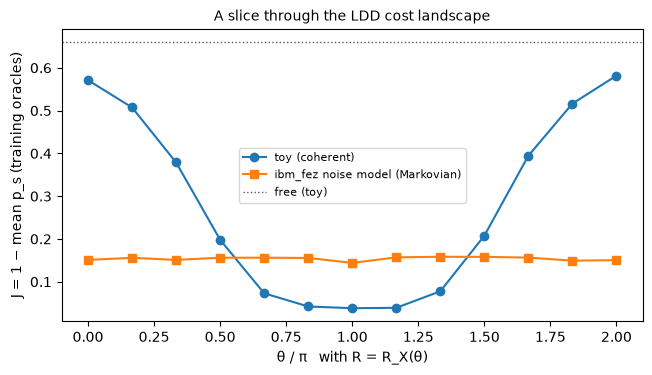

In [15]:
thetas = np.linspace(0, 2 * np.pi, 13)
X_SLICE = np.column_stack([thetas, np.full_like(thetas, -np.pi / 2), np.full_like(thetas, np.pi / 2)])
slice_pubs = [(circuits["ldd"][i], X_SLICE) for i in TRAIN_IDX]
J_slice = {"toy (coherent)": training_cost(run_offline(slice_pubs, 4 * TRAIN_SHOTS, "toy")),
           f"{backend.name} noise model (Markovian)": training_cost(run_offline(slice_pubs, 4 * TRAIN_SHOTS, "noisy"))}

fig, ax = plt.subplots(figsize=(7.5, 3.8))
for (name, J), style in zip(J_slice.items(), ["-o", "-s"]):
    ax.plot(thetas / np.pi, J, style, label=name)
ax.axhline(TOY_REF["free"], color=VARIANT_COLORS["free"], ls=":", lw=1, label="free (toy)")
ax.set_xlabel("θ / π   with R = R_X(θ)")
ax.set_ylabel("J = 1 − mean p_s (training oracles)")
ax.set_title("A slice through the LDD cost landscape", fontsize=10)
ax.legend(fontsize=8)
plt.show()

### 8c. Run the closed loop offline

Exactly the code that will run on hardware (§10), with the `"toy"` engine and no log file:
* 1 calibration evaluation, then `TOY_SPSA_MAXITER` = 30 iterations (the toy converges in about 5; the hardware loop
  runs `SPSA_MAXITER` = 100);
* `TRAIN_SHOTS` shots per oracle per point, the same statistics the hardware loop will see.

**Pass condition:** J falls from its $x_0$ value to the level of the best LDD reference point in §8a (R = X). The loop gets
no hint that an echo exists; it has to find one.

LDD is **not** expected to beat XX in this toy. The LDD family contains X X X X (R = X), so learning can do no better than the
best R. In addition, LDD needs gaps longer than 48 dt, against 12 dt for XX, so more short gaps stay bare (§3c). On hardware,
LDD's extra freedom (any axis, any angle) can pay off against error sources this toy leaves out.

calibrated a = 17.88;  J at x0 ≈ 0.541  ->  last pair mean J = 0.041


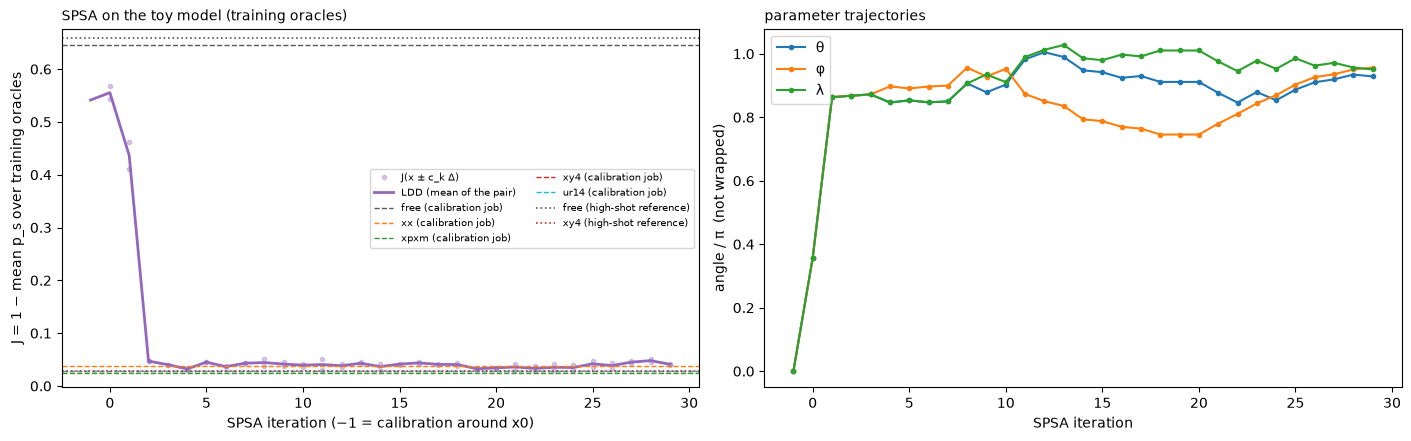

,θ/π,φ/π,λ/π,R: rotation (deg),"R: axis (x, y, z)"
,,,,,
learned (toy),0.929,0.957,0.951,167.295,"(+0.01, -1.00, -0.02)"
x0 (start),0.000,0.000,0.000,0.000,"(-0.00, +0.00, -0.00)"
X-point,-1.000,-0.500,0.500,180.000,"(+1.00, +0.00, -0.00)"
Y-point,-1.000,0.000,0.000,180.000,"(-0.00, +1.00, -0.00)"


In [16]:
toy_trainer = LddTrainer("toy")
x_toy, a_toy, toy_history = spsa_minimize(toy_trainer, TOY_SPSA_MAXITER)
print(f"calibrated a = {a_toy:.2f};  J at x0 ≈ {toy_history[0]['J']:.3f}  ->  last pair mean J = {toy_history[-1]['J']:.3f}")
plot_learning(toy_history, toy_trainer.baselines(), "SPSA on the toy model (training oracles)", "bv6_ldd_toy_learning.png",
              reference={"free": TOY_REF["free"], "xy4": TOY_REF["xy4"]})
display(param_table({"learned (toy)": x_toy, "x0 (start)": X0, "X-point": X_POINT, "Y-point": Y_POINT}))

### 8d. Toy model: the full final comparison with the toy-learned x\*

This is a dry run of the exact final batch (§11) and the analysis (§12), on the toy model:
* every oracle in `ORACLES` × 7 variants, `TOY_FINAL_SHOTS` shots each;
* none of these shots were used in training.

The key contrast is `ldd` against `ldd_x0`. The two have the same pulses at the same times, and only the learned virtual-Z
angles differ.

,mean p_s,±5σ,min p_s,oracles p_s > 1/2,Δ vs free,Δ 95% CI,oracles better than free
variant,,,,,,,
free,0.3420,0.0375,0.3420,0,0.0000,,
xx,0.9640,0.0147,0.9640,1,0.6220,"[+0.606, +0.638]",1
xpxm,0.9725,0.0129,0.9725,1,0.6305,"[+0.615, +0.646]",1
xy4,0.9738,0.0126,0.9738,1,0.6318,"[+0.616, +0.647]",1
ur14,0.9658,0.0144,0.9658,1,0.6238,"[+0.608, +0.639]",1
ldd,0.9570,0.0160,0.9570,1,0.6150,"[+0.599, +0.631]",1
ldd_x0,0.4310,0.0392,0.4310,0,0.0890,"[+0.068, +0.110]",1


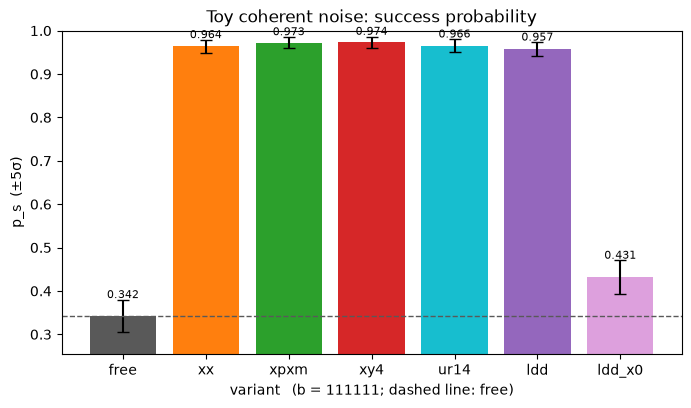

In [17]:
TOY_FINAL_SHOTS = max(400, 4000 // len(ORACLES))
toy_final = run_final_offline(x_toy, TOY_FINAL_SHOTS, "toy")
toy_ps = ps_table(toy_final)
display(summary_table(toy_ps, TOY_FINAL_SHOTS).round(4))
plot_ps_summary(toy_ps, TOY_FINAL_SHOTS, "Toy coherent noise: success probability", "bv6_ldd_toy_ps.png")

## 9. Noisy rehearsal and QPU budget

### 9a. Noisy local rehearsal (no QPU time)

The full final batch is run through `AerSimulator.from_backend`:
* `ldd` uses the hardware-learned x\* if one exists; otherwise it uses the toy x\*.
* The noise is Markovian only, so expect small differences between variants. Extra pulses mostly add gate error here.

This is a check of the data path (batch → counts → $p_s$ → tables and plots), not a prediction of the hardware result.

,mean p_s,±5σ,min p_s,oracles p_s > 1/2,Δ vs free,Δ 95% CI,oracles better than free
variant,,,,,,,
free,0.8498,0.0282,0.8498,1,0.0000,,
xx,0.8405,0.0289,0.8405,1,-0.0092,"[-0.025, +0.007]",0
xpxm,0.8470,0.0285,0.8470,1,-0.0028,"[-0.018, +0.013]",0
xy4,0.8388,0.0291,0.8388,1,-0.0110,"[-0.027, +0.005]",0
ur14,0.8465,0.0285,0.8465,1,-0.0032,"[-0.019, +0.012]",0
ldd,0.8432,0.0287,0.8432,1,-0.0065,"[-0.022, +0.009]",0
ldd_x0,0.8438,0.0287,0.8438,1,-0.0060,"[-0.022, +0.010]",0


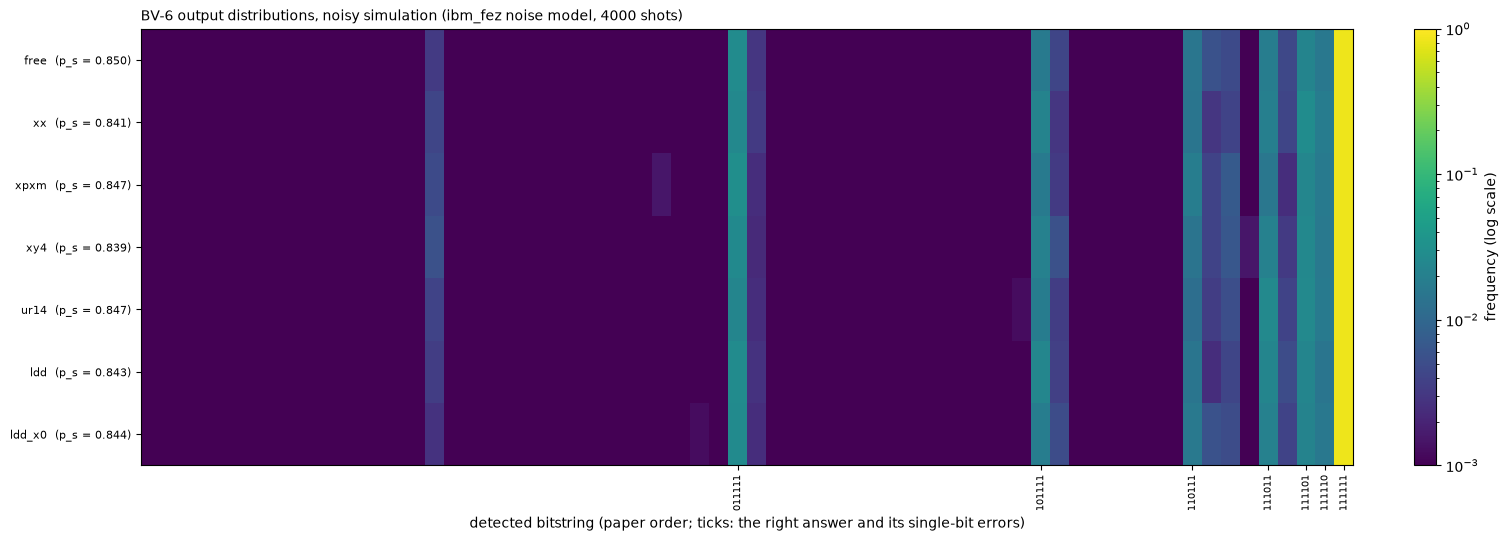

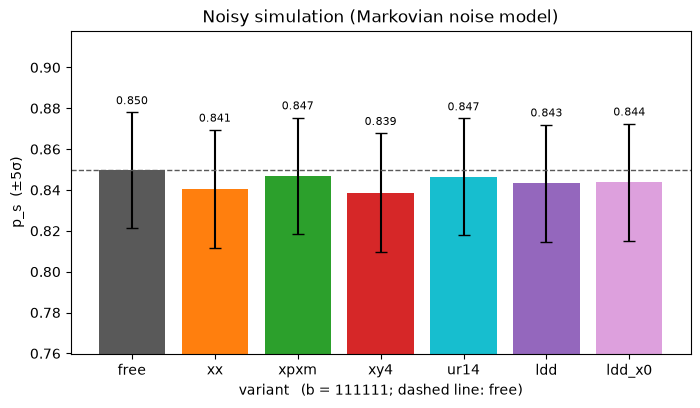

In [18]:
SHOTS_REHEARSAL = max(500, 4000 // len(ORACLES))
X_STAR_HW = None   # set in section 10 once hardware learning has run (or its log has been replayed)
x_rehearsal = x_toy
noisy_final = run_final_offline(x_rehearsal, SHOTS_REHEARSAL, "noisy")
noisy_ps = ps_table(noisy_final)
display(summary_table(noisy_ps, SHOTS_REHEARSAL).round(4))
plot_output_distributions(noisy_final, noisy_ps, f"BV-6 output distributions, noisy simulation ({backend.name} noise model, "
          f"{SHOTS_REHEARSAL} shots)", "bv6_ldd_fig2_noisy_sim.png")
plot_ps_summary(noisy_ps, SHOTS_REHEARSAL, "Noisy simulation (Markovian noise model)", "bv6_ldd_noisy_ps.png")

### 9b. QPU budget

The total cap is `QPU_BUDGET_SECONDS` (240 s), split into two parts:
* **learning**: the calibration job plus SPSA iterations, `LEARN_BUDGET_SECONDS`;
* **final job**: the remainder.

**Cost model per job:** a fixed overhead plus shots × (circuit duration + repetition delay).
* With an IBM connection, the overhead and the per-shot cost are **fitted** from the billed `usage()` of the project's earlier
  jobs (a line through usage vs. shots).
* Otherwise a conservative 5 s overhead is assumed.

SPSA runs `SPSA_MAXITER` = 100 iterations, as in the paper. Small jobs are billed far below the cost model: the first
`ibm_fez` run billed 29 s for calibration plus 31 iterations, where the model expected about 110 s. So once a training log
exists for this backend, the learning projection prices each remaining job at the usage **actually billed** per job so far
(every run keeps the same shots per job). Either way, the ledger in §10
tracks billed usage and stops the loop before it would exceed `LEARN_BUDGET_SECONDS`.

**Signal vs. shot noise on hardware.** The walkthrough's UR-14 gain was about +0.04 in $p_s$, so on hardware J will differ
between parameter points by a few percent. One evaluation (`TRAIN_SHOTS_PER_POINT` = 1750 shots) has σ_J ≈ 0.01, which is the same order.
If the hardware learning curve is still wandering at the end, raise `TRAIN_SHOTS_PER_POINT` (and with it the cost per iteration)
before adding iterations.

In [19]:
LEARN_BUDGET_SECONDS = 110
FINAL_BUDGET_SECONDS = 130
QPU_BUDGET_SECONDS = LEARN_BUDGET_SECONDS + FINAL_BUDGET_SECONDS   # 240
SHOTS_FINAL = 10_000 if len(ORACLES) == 1 else 1000   # per circuit: 7 x 10k for b = 111111 alone
DEFAULT_JOB_OVERHEAD_S = 5.0
PAST_JOB_IDS = ["dapdo9gr7bnc73b38qeg", "dapdo9ic505c73ci1a70", "dapdo9sak42c73cidgk0", "dapdoa2c505c73ci1a80",
                WALKTHROUGH_HW_JOB]   # Experiment 1 (free+UR-14, XX, XpXm, XY4) and the walkthrough job

rep_delay = getattr(backend.configuration(), "default_rep_delay", 250e-6) or 250e-6
rep_delay = rep_delay * 1e-6 if rep_delay > 1e-2 else rep_delay   # tolerate a value reported in us
per_shot_model = float(np.mean([c.estimate_duration(target, unit="s") for c in circuits["ldd"]])) + rep_delay

fit_points = []
if service is not None:
    for jid in PAST_JOB_IDS:
        try:
            past = service.job(jid)
            shots = 0
            for pub in past.result():
                bits = next(iter(pub.data.values()))
                shots += bits.num_shots * int(np.prod(bits.shape) or 1)
            fit_points.append((shots, float(past.usage())))
        except Exception as exc:
            print(f"(could not read job {jid}: {exc})")
if len(fit_points) >= 2:
    slope, intercept = np.polyfit(*np.array(fit_points).T, 1)
    JOB_OVERHEAD_S, PER_SHOT_S = max(float(intercept), 0.0), max(float(slope), per_shot_model)
    cost_source = f"fitted from {len(fit_points)} past jobs (overhead {intercept:.2f} s, {slope * 1e3:.3f} ms/shot)"
else:
    JOB_OVERHEAD_S, PER_SHOT_S = DEFAULT_JOB_OVERHEAD_S, per_shot_model
    cost_source = f"default model ({DEFAULT_JOB_OVERHEAD_S:.0f} s overhead, {per_shot_model * 1e3:.3f} ms/shot)"


def job_seconds(total_shots: int) -> float:
    return JOB_OVERHEAD_S + total_shots * PER_SHOT_S


def est_seconds(pubs, shots: int) -> float:
    return job_seconds(sum(pub_rows(X) for _, X in pubs) * shots)


n_train = len(TRAIN)
calib_s = job_seconds((2 * SPSA_CAL_PAIRS + len(BASELINE_VARIANTS)) * n_train * TRAIN_SHOTS)
iter_s = job_seconds(2 * n_train * TRAIN_SHOTS)
final_s = job_seconds(len(FINAL_VARIANTS) * len(ORACLES) * SHOTS_FINAL)
final_ok = final_s <= FINAL_BUDGET_SECONDS

# Learning projection for SPSA_MAXITER iterations. What this training log has already been billed, plus the remaining
# jobs priced at the usage actually billed per job in this backend's training logs (every run keeps the same shots per
# job, TRAIN_SHOTS_PER_POINT), falling back to the cost model when there is no billing history yet.
all_logs = {p: json.loads(p.read_text())["evals"] for p in sorted(RESULTS_DIR.glob(f"bv6_ldd_train_{backend.name}*.json"))}
current = all_logs.get(TRAIN_LOG, {})
spent_learn = sum(e.get("usage_s") or 0.0 for e in current.values())
done_iters = sum(1 for key, e in current.items() if key.startswith("iter_") and "J" in e)
billed_iter = [e.get("usage_s") or 0.0 for ev in all_logs.values() for key, e in ev.items() if key.startswith("iter_") and "J" in e]
billed_calib = [ev["calib"].get("usage_s") or 0.0 for ev in all_logs.values() if "J" in ev.get("calib", {})]
per_iter = float(np.mean(billed_iter)) if billed_iter else iter_s
calib_cost = 0.0 if "J" in current.get("calib", {}) else (float(np.mean(billed_calib)) if billed_calib else calib_s)
learn_projection = spent_learn + calib_cost + max(0, SPSA_MAXITER - done_iters) * per_iter
learn_source = (f"log {TRAIN_LOG.name}: {spent_learn:.0f} s billed, {done_iters} iterations done; "
                + (f"{per_iter:.2f} s per iteration billed on average over {len(billed_iter)} past iterations"
                   if billed_iter else "cost model, no billing history yet"))
learn_ok = spent_learn + iter_s <= LEARN_BUDGET_SECONDS   # room for at least one more job

print(f"Cost model: {cost_source}")
display(pd.DataFrame([
    {"item": "calibration job", "jobs": 1, "shots": (2 * SPSA_CAL_PAIRS + len(BASELINE_VARIANTS)) * n_train * TRAIN_SHOTS,
     "est. QPU s": calib_s},
    {"item": "SPSA iterations", "jobs": SPSA_MAXITER, "shots": SPSA_MAXITER * 2 * n_train * TRAIN_SHOTS,
     "est. QPU s": SPSA_MAXITER * iter_s},
    {"item": "final comparison", "jobs": 1, "shots": len(FINAL_VARIANTS) * len(ORACLES) * SHOTS_FINAL, "est. QPU s": final_s},
]).set_index("item").round(1))
print(f"Learning: {SPSA_MAXITER} SPSA iterations -> projected {learn_projection:.1f} s of {LEARN_BUDGET_SECONDS} s "
      f"({learn_source})")
if learn_projection > LEARN_BUDGET_SECONDS:
    print("  WARNING: the projection exceeds the learning budget, so the ledger will stop the loop early. "
          "Raise LEARN_BUDGET_SECONDS or lower TRAIN_SHOTS_PER_POINT.")
print(f"Final job: {final_s:.1f} s of {FINAL_BUDGET_SECONDS} s -> {'OK' if final_ok else 'OVER BUDGET: lower SHOTS_FINAL'}")

(could not read job dapdo9gr7bnc73b38qeg: 'Job not found: dapdo9gr7bnc73b38qeg')
(could not read job dapdo9ic505c73ci1a70: 'Job not found: dapdo9ic505c73ci1a70')
(could not read job dapdo9sak42c73cidgk0: 'Job not found: dapdo9sak42c73cidgk0')
(could not read job dapdoa2c505c73ci1a80: 'Job not found: dapdoa2c505c73ci1a80')
(could not read job dar140akqcdc73abf3b0: 'Job not found: dar140akqcdc73abf3b0')
Cost model: default model (5 s overhead, 0.253 ms/shot)


,jobs,shots,est. QPU s
item,,,
calibration job,1,43750,16.1
SPSA iterations,100,350000,588.6
final comparison,1,70000,22.7


Learning: 100 SPSA iterations -> projected 62.4 s of 110 s (log bv6_ldd_train_ibm_fez_b111111.json: 0 s billed, 0 iterations done; 0.48 s per iteration billed on average over 31 past iterations)
Final job: 22.7 s of 130 s -> OK


## 10. Hardware: learn x\*

**This cell spends QPU quota when `SUBMIT_LEARN = True`.** Before turning it on:
1. Set `USE_FAKE_BACKEND = False` in §0 and rerun everything above, so the circuits are built against the live calibration.
2. Check that the gates in §2/§5 pass and that the budget in §9b prints a sensible `SPSA_MAXITER`.

**How it runs:**
* The loop runs one job per iteration. On the Open Plan each job waits in the queue, so learning can take hours.
* Everything is written to `TRAIN_LOG` (`results/bv6_ldd_train_<backend>_<training set>.json`) as it happens.
* **To resume** after a restart, rerun the notebook and this cell. Finished evaluations are replayed from the log, a queued
  job is re-attached, and only missing iterations are submitted.
* With `SUBMIT_LEARN = False`, an existing log is replayed read-only. That recovers x\* and the plots without spending anything.

calib: submitted job davjgfo4oijs73e7m3hg (estimated 16.1 s QPU)
iter_000: submitted job davkaslj371s73dn2skg (estimated 5.9 s QPU)
iter_001: submitted job davkf72l7guc73cf2r30 (estimated 5.9 s QPU)
iter_002: submitted job davkgak92g1c739935gg (estimated 5.9 s QPU)
iter_003: submitted job davkgelj371s73dn36n0 (estimated 5.9 s QPU)
iter_004: submitted job davkh4492g1c739936d0 (estimated 5.9 s QPU)
iter_005: submitted job davkh75j371s73dn37h0 (estimated 5.9 s QPU)
iter_006: submitted job davkh9dj371s73dn37jg (estimated 5.9 s QPU)
iter_007: submitted job davkhg492g1c739936q0 (estimated 5.9 s QPU)
iter_008: submitted job davkhiil7guc73cf2uc0 (estimated 5.9 s QPU)
iter_009: submitted job davkhns92g1c73993730 (estimated 5.9 s QPU)
iter_010: submitted job davkivil7guc73cf30ag (estimated 5.9 s QPU)
iter_011: submitted job davkj284oijs73e7o60g (estimated 5.9 s QPU)
iter_012: submitted job davkj4s92g1c73993900 (estimated 5.9 s QPU)
iter_013: submitted job davkjail7guc73cf30v0 (estimated 5.9 s QP

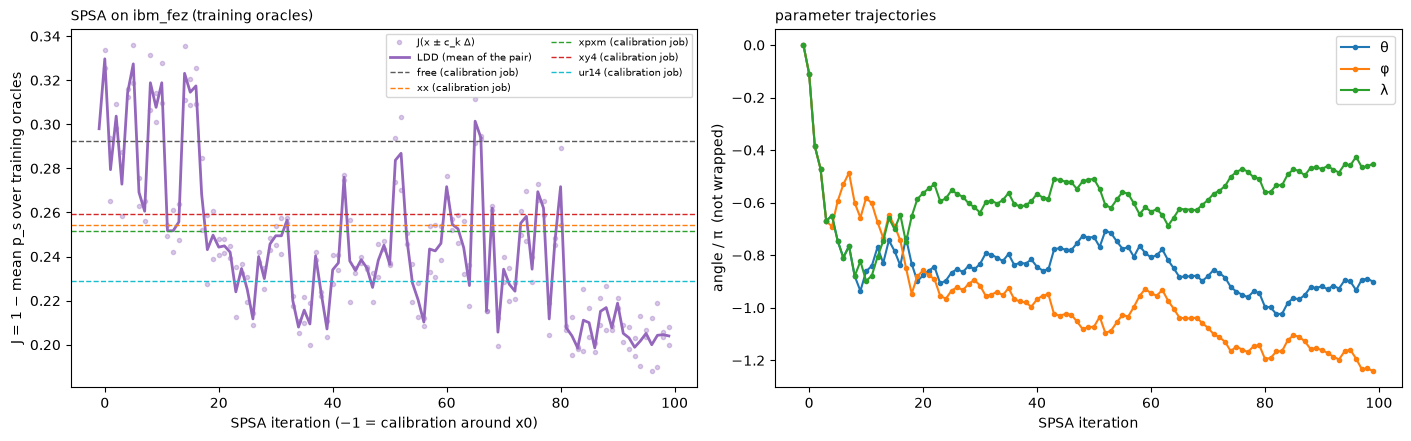

,θ/π,φ/π,λ/π,R: rotation (deg),"R: axis (x, y, z)"
,,,,,
learned (ibm_fez),-0.901,0.759,-0.451,164.197,"(+0.94, +0.32, +0.07)"
learned (toy),0.929,0.957,0.951,167.295,"(+0.01, -1.00, -0.02)"
X-point,-1.000,-0.500,0.500,180.000,"(+1.00, +0.00, -0.00)"
Y-point,-1.000,0.000,0.000,180.000,"(-0.00, +1.00, -0.00)"


In [20]:
SUBMIT_LEARN = True

hw_trainer, hw_history = None, []
if SUBMIT_LEARN:
    if USE_FAKE_BACKEND:
        raise RuntimeError("Set USE_FAKE_BACKEND = False and rebuild the circuits against the live backend first.")
    if not learn_ok:
        raise RuntimeError("No learning budget left for another SPSA iteration (see section 9b).")
if SUBMIT_LEARN or TRAIN_LOG.exists():
    hw_trainer = LddTrainer("hardware", log_path=TRAIN_LOG, budget_s=LEARN_BUDGET_SECONDS, est_seconds=est_seconds,
                            allow_submit=SUBMIT_LEARN)
    n_logged = sum(key.startswith("iter_") for key in hw_trainer.log["evals"])
    maxiter = max(SPSA_MAXITER, n_logged) if SUBMIT_LEARN else n_logged
    x_hw, a_hw, hw_history = spsa_minimize(hw_trainer, maxiter)
    if len(hw_history) > 1:
        X_STAR_HW = x_hw
        hw_trainer.log.update({"x_star": x_hw.tolist(), "iterations": len(hw_history) - 1, "a": a_hw})
        hw_trainer.save()
    print(f"{len(hw_history) - 1 if hw_history else 0} SPSA iterations available; "
          f"QPU used for learning: {hw_trainer.spent_s:.1f} s of {LEARN_BUDGET_SECONDS} s")
    if X_STAR_HW is not None:
        print(f"Learned x* = {np.round(wrap(X_STAR_HW), 3)}  (log: {TRAIN_LOG})")
        plot_learning(hw_history, hw_trainer.baselines(), f"SPSA on {backend.name} (training oracles)",
                      f"bv6_ldd_learning_{backend.name}.png")
        display(param_table({f"learned ({backend.name})": X_STAR_HW, "learned (toy)": x_toy,
                             "X-point": X_POINT, "Y-point": Y_POINT}))
else:
    print("SUBMIT_LEARN is False and there is no training log yet: no hardware learning.")

## 11. Hardware: the final comparison

**This cell spends QPU quota when `SUBMIT_FINAL = True`.** It needs a learned x\* from §10 and the budget check in §9b.

* One `SamplerV2` job: 7 variants × the oracles in `ORACLES` × `SHOTS_FINAL` shots, oracle-major, with Runtime DD and
  twirling off. For $b = 111111$ alone that is 7 circuits × 10 000 shots, about 70 000 shots.
* Run it soon after learning. The LDD paper re-evaluated two days later and found the parameters stable, but there is no
  reason to test that here.
* A record with the job ID and x\* is written to `results/` immediately, before the job runs.
* If a final job for the **same x\*** is already recorded in `results/`, rerunning this cell re-attaches to that job
  instead of paying for it twice. A new x\* (for example after more SPSA iterations) gets a new job.

In [21]:
SUBMIT_FINAL = True

final_job = None
if SUBMIT_FINAL:
    if USE_FAKE_BACKEND:
        raise RuntimeError("Set USE_FAKE_BACKEND = False and rebuild the circuits against the live backend first.")
    if X_STAR_HW is None:
        raise RuntimeError("No learned x*: run section 10 first.")
    previous = [json.loads(p.read_text()) for p in sorted(RESULTS_DIR.glob(f"bv6_ldd_final_{backend.name}_*.json"))]
    same_x = [r for r in previous if np.allclose(r.get("x_star", [np.nan] * 3), X_STAR_HW)
              and r.get("oracles") == ORACLES and r.get("variants") == FINAL_VARIANTS]
    if same_x:
        final_job = service.job(same_x[-1]["job_id"])
        print(f"A final job for this x* already exists ({final_job.job_id()}): re-attaching instead of resubmitting.")
    else:
        if not final_ok:
            raise RuntimeError("Over budget: lower SHOTS_FINAL (section 9b).")
        final_job = submit_hardware([(c, None) for c in final_batch(X_STAR_HW)], SHOTS_FINAL)
        record = {"job_id": final_job.job_id(), "backend": backend.name, "shots": SHOTS_FINAL, "seed": SEED,
                  "layout": LAYOUT, "x_star": X_STAR_HW.tolist(), "variants": FINAL_VARIANTS, "oracles": ORACLES,
                  "train_log": str(TRAIN_LOG), "submitted_utc": utc_now()}
        (RESULTS_DIR / f"bv6_ldd_final_{backend.name}_{final_job.job_id()}.json").write_text(json.dumps(record, indent=1))
        print(f"Submitted job {final_job.job_id()} on {backend.name}: {len(final_index())} circuits x {SHOTS_FINAL} shots")
else:
    print("SUBMIT_FINAL is False: no hardware job submitted.")

Submitted job davl135j371s73dn40v0 on ibm_fez: 7 circuits x 10000 shots


### 11b. Collect the final job (or reload it by ID)

`job.result()` blocks until the job has run. After a kernel restart, put the job ID in `FINAL_JOB_ID` and rerun with
`USE_FAKE_BACKEND = False`. The counts are positionally aligned with `final_index()`, which only depends on the variant list
and the oracle order.

In [22]:
FINAL_JOB_ID = None   # e.g. "d3abc..." to reload a finished job

hw_final, final_record = None, None
if final_job is None and FINAL_JOB_ID and service is not None:
    final_job = service.job(FINAL_JOB_ID)
if final_job is not None:
    record_path = RESULTS_DIR / f"bv6_ldd_final_{backend.name}_{final_job.job_id()}.json"
    final_record = json.loads(record_path.read_text()) if record_path.exists() else {}
    if final_record.get("variants", FINAL_VARIANTS) != FINAL_VARIANTS:
        raise RuntimeError("This job was submitted with a different variant list; set INCLUDE_LDD_X0 to match.")
    if final_record.get("oracles", ORACLES) != ORACLES:
        raise RuntimeError(f"This job ran {len(final_record['oracles'])} oracles; set ORACLES (section 1) to match.")
    counts = [rows[0] for rows in collect_hardware(final_job, [(None, None)] * len(final_index()))]
    hw_final = split_final(counts)
    final_record.update({"job_id": final_job.job_id(), "backend": backend.name, "counts": hw_final,
                         "saved_utc": utc_now()})
    final_record.setdefault("shots", SHOTS_FINAL)
    record_path.write_text(json.dumps(final_record, indent=1))
    print(f"Saved counts to {record_path}")
else:
    print("No final hardware job to collect.")

Saved counts to results\bv6_ldd_final_ibm_fez_davl135j371s73dn40v0.json


## 12. Results on hardware

,mean p_s,±5σ,min p_s,oracles p_s > 1/2,Δ vs free,Δ 95% CI,oracles better than free
variant,,,,,,,
free,0.7644,0.0212,0.7644,1,0.0000,,
xx,0.7987,0.0200,0.7987,1,0.0343,"[+0.023, +0.046]",1
xpxm,0.8041,0.0198,0.8041,1,0.0397,"[+0.028, +0.051]",1
xy4,0.8101,0.0196,0.8101,1,0.0457,"[+0.034, +0.057]",1
ur14,0.7937,0.0202,0.7937,1,0.0293,"[+0.018, +0.041]",1
ldd,0.7999,0.0200,0.7999,1,0.0355,"[+0.024, +0.047]",1
ldd_x0,0.7600,0.0214,0.7600,1,-0.0044,"[-0.016, +0.007]",0


Walkthrough (dar140akqcdc73abf3b0): paper_free 0.783 -> paper_ur14 0.821.  BV paper Fig. 2 (Cairo, UR-18): 59.9% -> 74.7%.


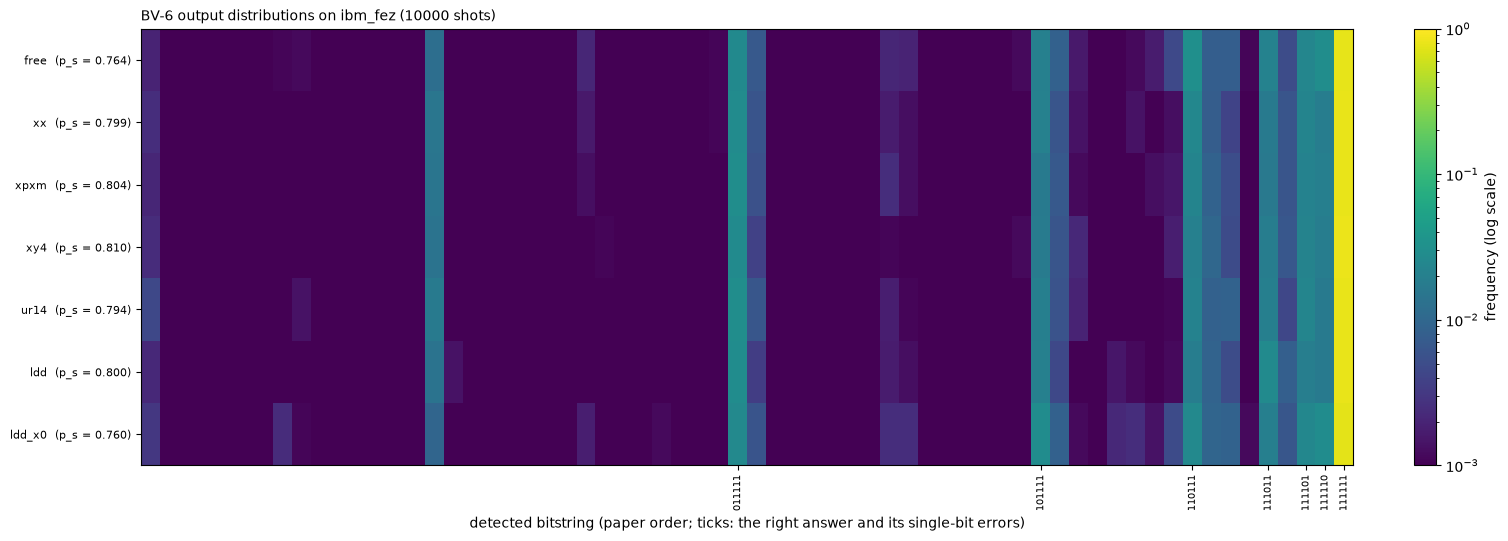

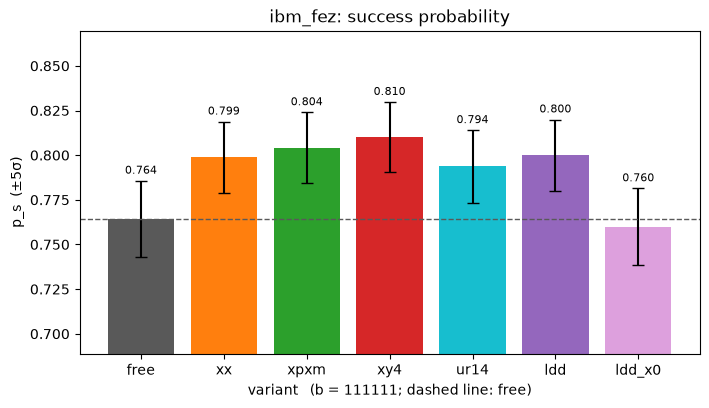

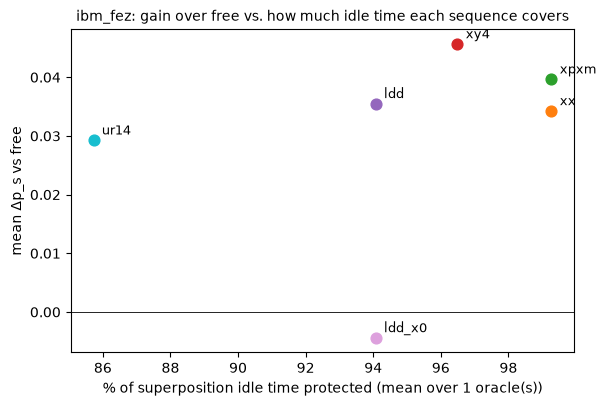

,free,xx,xpxm,xy4,ur14,ldd,ldd_x0
weight,,,,,,,
6,0.764,0.799,0.804,0.81,0.794,0.8,0.76


,θ/π,φ/π,λ/π,R: rotation (deg),"R: axis (x, y, z)"
,,,,,
"learned (ibm_fez), used in this job",-0.901,0.759,-0.451,164.197,"(+0.94, +0.32, +0.07)"
X-point,-1.000,-0.500,0.500,180.000,"(+1.00, +0.00, -0.00)"
Y-point,-1.000,0.000,0.000,180.000,"(-0.00, +1.00, -0.00)"


Mean p_s over this run's oracles in every hardware job on these qubits (earlier LDD jobs used their own x*; the walkthrough's UR-14 axes are the mirror image):


,submitted (UTC),free,xx,xpxm,xy4,ur14,ldd,ldd_x0
job,,,,,,,,
davl135j371s73dn40v0 (this job),2026-10-02T06:34,0.764,0.799,0.804,0.810,0.794,0.800,0.760
davi3g84oijs73e7j66g,2026-10-02T03:15,0.765,0.805,0.809,0.821,0.795,0.795,0.772
davibkk92g1c7398uqog,2026-10-02T03:32,0.788,0.803,0.817,0.836,0.799,0.803,0.775
dar140akqcdc73abf3b0 (walkthrough),2026-09-25T06:19,0.713,NaN,NaN,NaN,0.754,NaN,NaN


In [23]:
if hw_final is not None:
    shots = final_record["shots"]
    hw_ps = ps_table(hw_final)
    display(summary_table(hw_ps, shots).round(4))
    print(f"Walkthrough ({WALKTHROUGH_HW_JOB}): paper_free 0.783 -> paper_ur14 0.821.  "
          "BV paper Fig. 2 (Cairo, UR-18): 59.9% -> 74.7%.")
    plot_output_distributions(hw_final, hw_ps, f"BV-6 output distributions on {backend.name} ({shots} shots)",
              f"bv6_ldd_fig2_{backend.name}.png")
    plot_ps_summary(hw_ps, shots, f"{backend.name}: success probability", f"bv6_ldd_ps_{backend.name}.png")
    plot_gain_vs_coverage(hw_ps, f"{backend.name}: gain over free vs. how much idle time each sequence covers",
                          f"bv6_ldd_gain_vs_coverage_{backend.name}.png")
    display(hw_ps.groupby("weight")[FINAL_VARIANTS].mean().round(3))
    x_used = np.array(final_record.get("x_star", X_STAR_HW))
    display(param_table({f"learned ({backend.name}), used in this job": x_used, "X-point": X_POINT, "Y-point": Y_POINT}))

    # Earlier hardware jobs on the same qubits, restricted to the oracles of this run: a drift / reproducibility check.
    def ps_at_oracles(counts_by_variant, oracles_run, variant):
        cs = counts_by_variant.get(variant)
        if cs is None or not all(b in oracles_run for b in ORACLES):
            return np.nan
        return float(np.mean([success_prob(cs[oracles_run.index(b)], b) for b in ORACLES]))

    history = [{"job": final_record["job_id"] + " (this job)", "submitted (UTC)": final_record.get("submitted_utc", "")[:16],
                **{v: hw_ps[v].mean() for v in FINAL_VARIANTS}}]
    for path in sorted(RESULTS_DIR.glob(f"bv6_ldd_final_{backend.name}_*.json")):
        r = json.loads(path.read_text())
        if r.get("job_id") != final_record["job_id"] and "counts" in r and r.get("layout") == LAYOUT:
            history.append({"job": r["job_id"], "submitted (UTC)": r.get("submitted_utc", "")[:16],
                            **{v: ps_at_oracles(r["counts"], r["oracles"], v) for v in FINAL_VARIANTS}})
    old_path = RESULTS_DIR / f"bv6_fig1_{backend.name}_{WALKTHROUGH_HW_JOB}.json"
    if old_path.exists() and LAYOUT == WALKTHROUGH_HW_LAYOUT:
        old = json.loads(old_path.read_text())
        history.append({"job": WALKTHROUGH_HW_JOB + " (walkthrough)", "submitted (UTC)": old.get("saved_utc", "")[:16],
                        "free": ps_at_oracles(old["counts"], old["oracles"], "paper_free"),
                        "ur14": ps_at_oracles(old["counts"], old["oracles"], "paper_ur14")})
    print(f"Mean p_s over this run's oracles in every hardware job on these qubits (earlier LDD jobs used their own x*; "
          f"the walkthrough's UR-14 axes are the mirror image):")
    display(pd.DataFrame(history).set_index("job").round(3))
else:
    print("No hardware results yet.")

## 13. How to read the outcome, and next steps

* **Correctness.** §2 and §5 prove that every variant computes BV: $p_s = 1$ in ideal simulation, for LDD at *any* x.
* **Does learning help?** Compare in this order:
  1. `ldd` against `ldd_x0`. Same pulses, same timing; only the virtual-Z angles differ. Any gap here is due to the learning
     alone.
  2. `ldd` against the best fixed sequence. That is the LDD paper's claim, there made against CPMG and XY4.
  3. Every variant against `free`. With `ORACLES = ALL_ORACLES`, also look at it as a function of Hamming weight: the gain
     should grow with weight, because more CNOTs mean longer superposition waits.
* **Coverage is a confounder, so plot it.** On Heron the CZ takes 84 ns and an X takes 24 ns, so long sequences miss short
  gaps. `plot_gain_vs_coverage` puts each sequence's gain next to the share of idle time it actually protected. The LDD paper
  makes the same point about short-CZ devices such as ibm_torino.
* **Learned parameters.** `param_table` turns x\* into a rotation angle and axis. A learned R near a π rotation about an
  xy-plane axis is a conventional echo. Anything else is a device-specific compromise between echoing and cancelling pulse
  errors.

**Next steps, once this works at n = 6:**
1. **Scale n** with the same three parameters: re-learn per n, as the LDD paper suggests the parameter count can stay constant.
2. **Per-qubit parameters** (3 × 7 = 21). More expressive, but SPSA needs more iterations.
3. **LDD with N = 2** (R, R†): 4 √X pulses instead of 8, so it fits the short Heron gaps that XX fits.
4. **Learn the pulse spacing** too, which the LDD paper lists as future work.
5. **UR-18** as an extra variant, to match the BV paper's Cairo Fig. 2 sequence.